# Исследование стартапов


## Введение

**Контекст:**<br>
Финансовая компания готовится выйти на рынок инвестиций в стартапы (покупка → развитие → перепродажа). Для этого требуется исследование исторических данных и подготовка единого датасета.

**Основные задачи:**
- Сформировать корректный датасет из разрозненных таблиц, определить ключи для объединения.
- Проверить данные на полноту, ошибки и искажения; зафиксировать принятые допущения.
- Оценить достоверность информации о сотрудниках и образовании.
- Интерпретировать сделки с ценой - 0 или 1 доллар.
- Проанализировать зависимость цены покупки от категории стартапа и числа раундов финансирования.
- Рассчитать и визуализировать ключевые метрики и динамику (стоимость, частота сделок, время до выхода и др.).
- Выделить признаки, которые могут указывать на повышенную вероятность успешной сделки.<br>

**Ограничения:**
- Данные неполные и потенциально смещённые.
- Требуется осторожная интерпретация и явная фиксация всех предположений.<br>

**Ожидаемый результат:**
- Чистый и структурированный датасет.
- Отчёт о проверках качества данных.
- Ответы на бизнес-вопросы с визуализациями.
- Набор потенциальных индикаторов успешных сделок.

**Описание данных**<br>
**Таблица `acquisition`**<br>
Содержит информацию о покупках одними компаниями других компаний:<br>
`id` — идентификатор покупки.<br>
`acquiring_company_id` — идентификатор покупающей компании.<br>
`acquired_company_id` — идентификатор покупаемой компании.<br>
`term_code` — варианты расчёта.<br>
`price_amount` — сумма сделки.<br>
`acquired_at` — дата сделки.<br>

**Таблица `company_and_rounds`**<br>
Содержит информацию о компаниях и раундах финансирования:<br>
`company ID` — идентификатор компании.<br>
`name` — название компании.<br>
`category code` — категория области деятельности компании.<br>
`status` — статус компании.<br>
`founded at` — дата инвестирования.<br>
`closed at` — дата закрытия компании.<br>
`domain` — официальный сайт компании.<br>
`network username` — ник компании в сети.<br>
`country code` — код страны компании.<br>
`investment rounds` — число инвестиционных раундов.<br>
`funding rounds` — число раундов финансирования.<br>
`funding total` — сумма финансирования.<br>
`milestones` — вехи финансирования.<br>
`funding round id` — идентификатор этапа финансирования.<br>
`company id` — идентификатор компании.<br>
`funded at` — дата финансирования.<br>
`funding round type` — тип финансирования.<br>
`raised amount` — сумма финансирования.<br>
`pre money valuation` — предварительная денежная оценка.<br>
`participants` — число участников.<br>
`is first round` — является ли раунд первым.<br>
`is last round` — является раунд последним.<br>

**Таблица `education`**<br>
Содержит информацию об образовании сотрудника:<br>
`id` — идентификатор записи об образовании.<br>
`person_id` — идентификатор работника.<br>
`instituition` — название учебного заведения.<br>
`graduated_at` — дата получения образования.<br>

**Таблица `people`**<br>
Содержит информацию о сотрудниках:<br>
`id` — идентификатор сотрудника.<br>
`first_name` — имя сотрудника.<br>
`last_name` — фамилия сотрудника.<br>
`company_id` — идентификатор компании.<br>
`network_username` — ник в социальных сетях.<br>

**Таблица `degrees`**<br>
Содержит информацию о типе образования сотрудника:<br>
`id` — идентификатор записи.<br>
`object_id` — идентификатор сотрудника.<br>
`degree_type` — тип образования.<br>
`subject` — специальность.<br>




## Шаг 1. Знакомство с данными: загрузка и первичная предобработка

Названия файлов:
* acquisition.csv
* company_and_rounds.csv
* people.csv
* education.csv
* degrees.csv

Опциональные датасеты:
* fund.csv
* investment.csv



### 1.1. Вывод общей информации, исправление названия столбцов

- Загрузим все данные по проекту.
- Проверим названия столбцов.
- Выведим информацию, которая необходима для принятия решений о предобработке, для каждого из датасетов.

Начнем с загрузки библиотек и данных о рынке стартапов. Будем использовать pandas и библиотеки визуализации данных matplotlib и seaborn, а также phik для построения матрицы корреляции. Данные датасетов сохраним в двух переменных: `acquisition_df`, `company_and_rounds_df`, `people_df`, `education_df`, `degrees_df`.

In [ ]:
# Импортируем библиотеки
import pandas as pd
pd.set_option('display.max_columns', None)  # Настроем отображение всех столбцов
pd.set_option('display.max_rows', None)  # Настроем отображение всех строк

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

# Импортируем библиотеку numpy для работы с числовыми данными,
# математическими операциями и обработкой пропущенных значений
import numpy as np

# Импортируем библиотеку matplotlib_venn
!pip install matplotlib-venn
from matplotlib_venn import venn2



In [ ]:
# Выгружаем данные в датафреймы acquisition_df, company_and_rounds_df, people_df, education_df, degrees_df
PATH = "https://code.s3.yandex.net/datasets/"
acquisition_df = pd.read_csv(PATH + 'acquisition.csv')
company_and_rounds_df = pd.read_csv(PATH + 'company_and_rounds.csv')
people_df = pd.read_csv(PATH + 'people.csv')
education_df = pd.read_csv(PATH + 'education.csv')
degrees_df = pd.read_csv(PATH + 'degrees.csv')


Познакомимся с данными датасета `datasets/acquisition.csv` — выведем первые сторки методом head() и общую информацию о датафрейме с помощью метода info():

In [ ]:
# Выводим первые строки датафрейма acquisition_df


print(
    '''
датафрейм acquisition_df

содержит информацию о покупках одними компаниями других компаний:
id — идентификатор покупки.
acquiring_company_id — идентификатор покупающей компании.
acquired_company_id — идентификатор покупаемой компании.
term_code — варианты расчёта.
price_amount — сумма сделки.
acquired_at — дата сделки.
'''
)

display(acquisition_df.head(10))


датафрейм acquisition_df

содержит информацию о покупках одними компаниями других компаний:
id — идентификатор покупки.
acquiring_company_id — идентификатор покупающей компании.
acquired_company_id — идентификатор покупаемой компании.
term_code — варианты расчёта.
price_amount — сумма сделки.
acquired_at — дата сделки.



,id,acquiring_company_id,acquired_company_id,term_code,price_amount,acquired_at
0,1,11,10,NaN,20000000,2007-05-30
1,7,59,72,cash,60000000,2007-07-01
2,8,24,132,cash,280000000,2007-05-01
3,9,59,155,cash,100000000,2007-06-01
4,10,212,215,cash,25000000,2007-07-01
5,11,227,228,NaN,7140000,2003-08-05
6,12,5,230,cash,0,2007-07-01
7,14,318,314,cash,0,2006-10-01
8,15,20,333,stock,1500000000,2002-07-08
9,16,342,341,cash,350000000,2007-08-01


In [ ]:
# Выводим информацию о датафрейме acquisition_df
acquisition_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9407 entries, 0 to 9406
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   id                    9407 non-null   int64 
 1   acquiring_company_id  9407 non-null   int64 
 2   acquired_company_id   9407 non-null   int64 
 3   term_code             1831 non-null   object
 4   price_amount          9407 non-null   int64 
 5   acquired_at           9378 non-null   object
dtypes: int64(4), object(2)
memory usage: 441.1+ KB


In [ ]:
# Создадим функцию, которая отобразит статистику по количеству и доле пропусков в датафрейме acquisition_df
def show_missing_stats(data_nan):
    """
    Функция для отображения статистики пропущенных значений в DataFrame.
    Параметры:   data_nan (pd.DataFrame): Исходный DataFrame для анализа
    Возвращает:  Styler или строку: Объект Styler с подсветкой или сообщение об отсутствии пропусков
    """
    missing_stats = pd.DataFrame({
        'Кол-во пропусков': data_nan.isnull().sum(),
        'Доля пропусков': data_nan.isnull().mean().round(4)
    })
    missing_stats = missing_stats[missing_stats['Кол-во пропусков'] > 0]
    return missing_stats.style.background_gradient(cmap='coolwarm') if not missing_stats.empty else "Пропусков в данных нет"
show_missing_stats(acquisition_df)

,Кол-во пропусков,Доля пропусков
term_code,7575,0.805300
acquired_at,29,0.003100


Датасет `datasets/acquisition.csv` содержит 9407 строк и 6 столбцов, в которых представлена информация о информацию о покупках одними компаниями других компаний.

После первичного знакомства с данными можно зафиксировать следующие:

- **Столбцы**: Названия столбцов имеют вид snake case, что является стандартом для работы с табличными данными. Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.
- **Тип данных**:Данные в столбцах представлены типом `object` и `int64`. Столбец `acquired_at` с типом данных `object` содержит сведения о дате сделки. Его нужно будет преобразовать к типу datetime64. Можно также понизить разрядность числовых данных в столбцах с индентификатором сделки и компаний: `id`, `acquiring_company_id`, `acquired_company_id`.
- **Пропуски**: Значительное количество пропусков 7579 или 80.5% содержатся в столцах `term_code` с информацией о вариантах расчёта и небольшое количество пропусков в `acquired_at`. В столбце `price_amount` встрачаются пропущенные значения, обозначенные 0.
- **Значения**: Идентификатор покупающей компании и идентификатор покупаемой компании представлены целочисленными значениями (1, 2, 3 и т.д.), то есть идентификаторы компаний могут совпадать. Из-за этого сложно определить речь идет об одних и тех же компаниях или нет.


Проверим уникальные значения в `id`, `acquiring_company_id`, `acquired_company_id`. Далее посмотрим на количество значений 0 в столбце `price_amount`.

In [ ]:
# Создадим функцию, которая отобразит уникальные значения в столбцах датафрейма
def print_count_uniq_values (dataframe, columns):
    """
    Функция для вывода на экран количество уникальные значения в указанных столбцах датафрейма.

    Параметры:
    dataframe (pd.DataFrame): датафрейм для анализа
    columns (list): список столбцов, для которых нужно подсчитать количество уникальных значений
    """
    print('Количество уникальных значений в столбцах датафрейма')
    print('Размер датафрейма:', dataframe.shape[0])
    print()
    for column in columns:
        print(f'Количество уникальных значений в {column}:', dataframe[column].value_counts().count())



In [ ]:
# Отобразим количество уникальных занчений в столбцах id, acquiring_company_id, acquired_company_id
columns_to_check = ['id', 'acquiring_company_id', 'acquired_company_id']
print_count_uniq_values(acquisition_df, columns_to_check)


Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 9407

Количество уникальных значений в id: 9407
Количество уникальных значений в acquiring_company_id: 4793
Количество уникальных значений в acquired_company_id: 9264


Все индентификаторы сделок уникальны: каждая строка — это уникальное событие покупки. 4793 уникальных покупателя в столбе `acquiring_company_id` указывает на то, что часть компании совершила несколько покупок. Заметим также, что в небольшая часть компаний (стартапов) в столбце `acquired_company_id` встречается не один раз — это говорит о том, что эти компании были куплены более одного раза. Необходимо проверить этот момент: посмотреть отдельно на проданные компании, чей индентификатор встречается более одного раза. Возможно в датафрейме есть неполные дубликаты.



In [ ]:
# Посчитаем количество неполных дубликатов по столбцам acquired_company_id и acquiring_company_id, с помощью метода duplicated()
acquisition_df.duplicated(subset=['acquired_company_id', 'acquiring_company_id']).sum()

np.int64(25)

In [ ]:
# Выведем проданные компании, чей индентификатор встречается более одного раза, с помощью метода duplicated()
acquisition_df[acquisition_df.duplicated(subset=['acquired_company_id', 'acquiring_company_id'], keep=False)].sort_values('acquired_company_id')

,id,acquiring_company_id,acquired_company_id,term_code,price_amount,acquired_at
7581,8454,317,1612,NaN,150000000,2013-03-29
7562,8435,317,1612,NaN,0,2013-03-28
1600,1875,317,2279,NaN,0,2008-08-24
620,762,317,2279,NaN,0,2008-08-25
429,542,59,10963,NaN,0,2008-09-12
2167,2484,59,10963,NaN,0,2008-09-12
589,725,317,13089,NaN,0,2008-10-20
2165,2481,317,13089,NaN,0,2008-10-22
9352,10469,157289,39040,NaN,0,2013-12-04
9355,10472,157289,39040,NaN,0,2013-12-04


По столбцам acquiring_company_id и acquired_company_id встречаются 25 неявных дубликатов: то есть данные о приобретении компанией одного и того же стартапа больше одного раза. Отметим особенности обнаруженных строк с дубликами:
- у них разные индентификаторы сделки;
- в одних случаях даты сделки разные (но близкие), в других одинаковые;
- варианты расчёта, кроме одного случая, одинаковые;
- в трех случаях указана сумма сделки;
- встречаются случаи когда компания покупает себя саму, что выглядит странно (например, компании с id 178137, 45891)

На этапе предобработки  можно будет удалить неполные дубликаты. Учитывая гетерогенный характер дубликатов, нужно будет использовать разные способы их удаления.

Проверим датафрейм на присутствие явных дубликатов.


In [ ]:
# Проверяем наличие явных дубликатов в датафрейме
acquisition_df.duplicated().sum()

np.int64(0)

Далее нам необходимо посмотреть на количество значений 0 в столбце, которые встречаются в столбце `price_amount`. Для этого создадим функцию.

In [ ]:
# Создадим функцию, которая отобразит количество значений без пропусков (NaN),
# количество значений 0 и количество значений без пропусков и 0 в столбцах датафрейма
def print_non_zero_values(dataframe, columns):
    """
    Функция для вывода на экран количества ненулевых значений в указанных столбцах датафрейма.

    Параметры:
    dataframe (pd.DataFrame): датафрейм для анализа
    columns (list): список столбцов, для которых нужно подсчитать количество ненулевых значений
    """
    print('Размер датафрейма:', dataframe.shape[0])
    print()
    for column in columns:
        print(f'Количество значений без пропусков (NaN) в {column}: ', dataframe.shape[0] - dataframe[column].isnull().sum())
        print(f'Количество значений 0 в {column}: ', (dataframe[column] == 0).sum())
        print(f'Количество значений без пропусков (NaN) и без 0 в {column}: ', dataframe.shape[0] - dataframe[column].isnull().sum() - (dataframe[column] == 0).sum())
        print('-' * 80)

In [ ]:
# Проверим на нулевые значения столбцы id, acquiring_company_id, acquired_company_id, price_amount.
columns_to_check = ['id', 'acquiring_company_id', 'acquired_company_id', 'price_amount']
print_non_zero_values(acquisition_df, columns_to_check)

Размер датафрейма: 9407

Количество значений без пропусков (NaN) в id:  9407
Количество значений 0 в id:  0
Количество значений без пропусков (NaN) и без 0 в id:  9407
--------------------------------------------------------------------------------
Количество значений без пропусков (NaN) в acquiring_company_id:  9407
Количество значений 0 в acquiring_company_id:  0
Количество значений без пропусков (NaN) и без 0 в acquiring_company_id:  9407
--------------------------------------------------------------------------------
Количество значений без пропусков (NaN) в acquired_company_id:  9407
Количество значений 0 в acquired_company_id:  0
Количество значений без пропусков (NaN) и без 0 в acquired_company_id:  9407
--------------------------------------------------------------------------------
Количество значений без пропусков (NaN) в price_amount:  9407
Количество значений 0 в price_amount:  6931
Количество значений без пропусков (NaN) и без 0 в price_amount:  2476
----------------------

Значения 0 встречаются только в поле `price_amount`. При этом их достаточно много: 6931. В итоге столбце `price_amount` содержить информацию о сумме сделки только для 2476 случаев продаж.

Далее познакомимся с данными датасета `datasets/company_and_rounds.csv`.

In [ ]:
# Выводим первые строки датафрейма company_and_rounds_df


print(
    '''
датафрейм company_and_rounds_df

Содержит информацию о компаниях и раундах финансирования:
company ID — идентификатор компании.
name — название компании.
category code — категория области деятельности компании.
status — статус компании.
founded at — дата инвестирования.
closed at — дата закрытия компании.
domain — официальный сайт компании.
network username — ник компании в сети.
country code — код страны компании.
investment rounds — число инвестиционных раундов.
funding rounds — число раундов финансирования.
funding total — сумма финансирования.
milestones — вехи финансирования.
funding round id — идентификатор этапа финансирования.
company id — идентификатор компании.
funded at — дата финансирования.
funding round type — тип финансирования.
raised amount — сумма финансирования.
pre money valuation — предварительная денежная оценка.
participants — число участников.
is first round — является ли раунд первым.
is last round — является раунд последним.
'''
)

display(company_and_rounds_df.head(10))


датафрейм company_and_rounds_df

Содержит информацию о компаниях и раундах финансирования:
company ID — идентификатор компании.
name — название компании.
category code — категория области деятельности компании.
status — статус компании.
founded at — дата инвестирования.
closed at — дата закрытия компании.
domain — официальный сайт компании.
network username — ник компании в сети.
country code — код страны компании.
investment rounds — число инвестиционных раундов.
funding rounds — число раундов финансирования.
funding total — сумма финансирования.
milestones — вехи финансирования.
funding round id — идентификатор этапа финансирования.
company id — идентификатор компании.
funded at — дата финансирования.
funding round type — тип финансирования.
raised amount — сумма финансирования.
pre money valuation — предварительная денежная оценка.
participants — число участников.
is first round — является ли раунд первым.
is last round — является раунд последним.



,company ID,name,category code,status,founded at,closed at,domain,network username,country code,investment rounds,funding rounds,funding total,milestones,funding round id,company id,funded at,funding round type,raised amount,pre money valuation,participants,is first round,is last round
0,1.0,Wetpaint,web,operating,2005-10-17,NaN,wetpaint-inc.com,BachelrWetpaint,USA,0.0,3.0,39750000.0,5.0,888.0,1.0,2005-10-01,series-a,5250000.0,0.0,2.0,0.0,1.0
1,1.0,Wetpaint,web,operating,2005-10-17,NaN,wetpaint-inc.com,BachelrWetpaint,USA,0.0,3.0,39750000.0,5.0,889.0,1.0,2007-01-01,series-b,9500000.0,0.0,3.0,0.0,0.0
2,1.0,Wetpaint,web,operating,2005-10-17,NaN,wetpaint-inc.com,BachelrWetpaint,USA,0.0,3.0,39750000.0,5.0,2312.0,1.0,2008-05-19,series-c+,25000000.0,0.0,4.0,1.0,0.0
3,10.0,Flektor,games_video,acquired,NaN,NaN,flektor.com,NaN,USA,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,100.0,There,games_video,acquired,NaN,NaN,there.com,NaN,USA,0.0,0.0,0.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,10000.0,MYWEBBO,network_hosting,operating,2008-07-26,NaN,mywebbo.com,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,10001.0,THE Movie Streamer,games_video,operating,2008-07-26,NaN,themoviestreamer.com,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,10002.0,Synergie Media,advertising,operating,2007-06-27,NaN,synergie-media.com,NaN,MAR,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,10003.0,Green Basti Ecosystems,cleantech,operating,2008-08-20,NaN,NaN,NaN,IND,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,100042.0,HostNine,NaN,operating,NaN,NaN,hostnine.com,Hostnine,NaN,0.0,0.0,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Выводим информацию о датафрейме company_and_rounds_df
company_and_rounds_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217774 entries, 0 to 217773
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   company  ID            217472 non-null  float64
 1   name                   217471 non-null  object 
 2   category  code         143886 non-null  object 
 3   status                 217472 non-null  object 
 4   founded  at            109956 non-null  object 
 5   closed  at             3449 non-null    object 
 6   domain                 147159 non-null  object 
 7   network  username      95534 non-null   object 
 8   country  code          108607 non-null  object 
 9   investment  rounds     217472 non-null  float64
 10  funding  rounds        217472 non-null  float64
 11  funding  total         217472 non-null  float64
 12  milestones             217472 non-null  float64
 13  funding  round  id     52928 non-null   float64
 14  company  id            52928 non-nul

In [ ]:
# Отобразим статистику по количеству и доле пропусков в датафрейме company_and_rounds_df

show_missing_stats(company_and_rounds_df)

,Кол-во пропусков,Доля пропусков
company ID,302,0.001400
name,303,0.001400
category code,73888,0.339300
status,302,0.001400
founded at,107818,0.495100
closed at,214325,0.984200
domain,70615,0.324300
network username,122240,0.561300
country code,109167,0.501300
investment rounds,302,0.001400


Датасет `datasets/company_and_rounds.csv` содержит 217774 строки и 22 столбца, в которых представлена информация о компаниях и раундах финансирования.

После первичного знакомства с данными можно зафиксировать следующие:

- **Оформление названия столбцов**: названия столбцов необходимо будет привести к виду `snake case`. В названиях также есть лишние пробелы.

- **Строки**: каждая строка содержит информацию об одном финансовом раунде компании, если он состоялся. В ином случаем в строке дана общая информация о компании.

- **Название и содержание столбцов**: есть несколько проблемных моментов. Прежде всего, есть два столбца с идентификаторами компаний: `company  ID` и `company  id`. При этом в первом в столбце `company  ID` есть незначительное количество пропусков, а в `company  id` их много. Скорее всего, это результат объединения двух изначально раздельных таблиц. Видно, что левая часть столбцов несет скорее общую информацию о компаниях, а правая информацию о раундах. <br> Есть близкие по смыслу столбцы: дата инвестирования `founded  at` и дата финансирования `funded  at`. По предварительной оценке, значения в них не совпадают и количество пропусков в них разное. Это указывает на то, что эти столбцы хранят разную инфомарцию. Однако остается не совсем ясно, чем отличается финансирование от инвестирования.<br>
Похожая история со столбцами `investment rounds` — число инвестиционных раундов и`funding rounds` — число раундов финансирования. Хотя количество пропусков в этих столбцах совпадает, видно, что значения в столбцах отличаются.<br>
Столбец `funding total` содержит общую сумму финансирования, столбец `raised amount` — сумма финансирования в рамках раунда.

- **Пропуски**: в датасете 217774 строки, пропуски содержатся во всех столбцах, но их количество варьируется. Самое большое количество пропусков  с столбце, который содержит информацию о дате закрытия компании `closed at` (214325 пропусков или 98.4%), что закономерно, а самое маленькое количество — в столбцах `company ID`, `name, status`, `investment rounds`, `funding rounds`, `funding total`, `milestones` (во всех 320 или 0.1%). Еще одно наблюдение: хотя в столбцах `investment  rounds`, `funding  rounds`, `funding  total`, `milestones` есть незначительное число пропусков, в них также встречаются значения 0. На этом этапе проверим, сколько таких значений в каждом столбце.  Только 52928 строк содержат информацию о раудах финансирования, сумме финансирования и т.д. (столбец `funded  at` имеет близкое количество строк — 52680), которые важны для заказчика.  Остальные значения в этих столбцах — пропуски. Таким образом, только эта часть датасета может быть рассмотрена в анализе отдельных компаний. Отметим, что все остальные операции по преобразованию, оптимизации нужно будет осуществить только после отбора строк.

- **Типы данных**: данные в столбцах представлены типом `object` и `float64`. Столбцы, содержащие текст, имеют соответствующий тип данных `object`: `name`, `category  code`, `status`, `domain`, `network username`, `country code`, `funding round type`. Столбцы с информацией о датах имеют тип данных `object`: `founded  at`, `closed  at`, `funded  at`. Их  нужно будет преобразовать к типу datetime64. Однако опять же перед преобразованием нужно будет оставить только те столбцы, которые будут использованы в анализе. В столбцах `milestones`, `funding round id`, `company id`, `participants`, `is first round`, `is last round` необходимо будет понизить разрядность. Но предварительно нужно будет проверить, какие значения они содержат.

Далее выполним следующие действия:<br>
1) приведем названия столбцов к виду `snake case`.<br>
2) поскольку в данных помимо пропусков встречаются нулевые значения, проверим количество значений 0 во всех столбцах с типом данных `float64`.<br>
3) отобразим количество уникальных занчений в столбцах.<br>
4) проверим наличие явных и неявных дубликатов

Изменим предварительно название первого столбца `company  ID` на `company_id_full`, чтобы не было дубликатов.

In [ ]:
# Передаём методу rename() словарь с названиями столбцов
company_and_rounds_df = company_and_rounds_df.rename(columns={'company  ID': 'company_id_full'})

In [ ]:
# Преобразуем названия столбцов в датафрейме company_and_rounds_df в формат snake_case:
# str.lower() — приводим все символы к нижнему регистру,
# str.replace(r'\s+', '_') заменяем пробелы на подчеркивания.
company_and_rounds_df.columns = company_and_rounds_df.columns.str.lower().str.replace(r'\s+', '_', regex=True)

In [ ]:
# Проверяем результат преобразования
display(company_and_rounds_df.columns)

Index(['company_id_full', 'name', 'category_code', 'status', 'founded_at',
       'closed_at', 'domain', 'network_username', 'country_code',
       'investment_rounds', 'funding_rounds', 'funding_total', 'milestones',
       'funding_round_id', 'company_id', 'funded_at', 'funding_round_type',
       'raised_amount', 'pre_money_valuation', 'participants',
       'is_first_round', 'is_last_round'],
      dtype='object')

Обратимся далее к оценке количества нулевых значений.

In [ ]:
# Отобразим информацию по всем столбцах с типом данных float64 из датафрейма company_and_rounds_df
columns_to_check = ['company_id_full', 'investment_rounds', 'funding_rounds', 'funding_total',
                    'milestones', 'funding_round_id', 'company_id', 'raised_amount',
                    'pre_money_valuation', 'participants', 'is_first_round', 'is_last_round']
print_non_zero_values(company_and_rounds_df, columns_to_check)



Размер датафрейма: 217774

Количество значений без пропусков (NaN) в company_id_full:  217472
Количество значений 0 в company_id_full:  0
Количество значений без пропусков (NaN) и без 0 в company_id_full:  217472
--------------------------------------------------------------------------------
Количество значений без пропусков (NaN) в investment_rounds:  217472
Количество значений 0 в investment_rounds:  214644
Количество значений без пропусков (NaN) и без 0 в investment_rounds:  2828
--------------------------------------------------------------------------------
Количество значений без пропусков (NaN) в funding_rounds:  217472
Количество значений 0 в funding_rounds:  164846
Количество значений без пропусков (NaN) и без 0 в funding_rounds:  52626
--------------------------------------------------------------------------------
Количество значений без пропусков (NaN) в funding_total:  217472
Количество значений 0 в funding_total:  169059
Количество значений без пропусков (NaN) и без 0 в 

Ранее мы обнаружили, что в столбцах `investment_rounds`, `funding_rounds`, `funding_total`, `milestones` встречаются значения 0. Мы провели дополнительную проверку и выяснили, что кроме `company_id_full`, `funding_round_id`, `company_id`, остальные стоблцы с типом числовым (вещественным) типом данных содержат значения 0. Количество нулевых значений варьируется от значительного, как в случае данных о числе инвестиционных раундов (значение 0 встречается 214644 раз) до небольшого, как например, в столбце raised  amount с информацией о сумме финансирования 6000.

Еще важное наблюдение. Дополнительный анализ показал, что, хотя в столбцах `investment_rounds` (число инвестиционных раундов) и `funding_rounds` (число раундов финансирования) совпадала количество значений без пропусков (NaN), в них разное количество нулевых значений. Это говорит в пользу того, что значения в этих столбцах различаются и они описывают разные сущности.

Далее посмотрим на количество уникальных значений в столбцах: `company_id_full`, `name`, `status`, `network_username`, `funding_round_id`, `company_id`, `investment_rounds`, `funding_rounds`, `funding_round_type`.

In [ ]:
# Отобразим количество уникальных занчений в столбцах company  ID, name, company  id, investment  rounds, funding  rounds
columns_to_check = ['company_id_full', 'name', 'status', 'network_username',
                    'funding_round_id', 'company_id', 'investment_rounds',
                    'funding_rounds', 'funding_round_type']
print_count_uniq_values(company_and_rounds_df, columns_to_check)


Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 217774

Количество уникальных значений в company_id_full: 196553
Количество уникальных значений в name: 196505
Количество уникальных значений в status: 4
Количество уникальных значений в network_username: 79571
Количество уникальных значений в funding_round_id: 52928
Количество уникальных значений в company_id: 31939
Количество уникальных значений в investment_rounds: 42
Количество уникальных значений в funding_rounds: 16
Количество уникальных значений в funding_round_type: 9


In [ ]:
# Отдельное посмотрим на количество уникальных значений в столбце status,
# который дальше будет необходим в анализе
display(company_and_rounds_df['status'].value_counts())
display(company_and_rounds_df['status'].value_counts(normalize=True).round(2))

,count
status,
operating,200486
acquired,11719
closed,3385
ipo,1882


,proportion
status,
operating,0.92
acquired,0.05
closed,0.02
ipo,0.01


Ранее мы обнаружили, что в датафрейме есть два столбца с идентификатором компании: `company_id_full` и `company_id`. В обоих столбцах мы обнаружили пропуски: 302 пропуска или 0,1% от количество всех строк датафрейма в `company_id_full` и 164846 пропусков или 75,7% в `company_id`. Кроме того, мы выяснили, что в обоих столбцах отсутствуют нулевые значения. Сейчас мы установили, что в обоих столбцах некоторые индентификаторы встречаются более одного раза. Стоит также обратить ванимание на то, что количество уникальный индентификаторов компании `company_id_full` немного больше, чем количество уникальных названий компании `name`, что скорее всего указывает на то, что у некоторых компаний одинаковые названия.

Столбец с ником компании в сети `network_username` содержит больше уникальных значений (79571), чем в `company_id`.

Также в столбцах `investment_rounds` (число инвестиционных раундов) и `funding_rounds` (число раундов финансирования) разное количество уникальных значений, что еще раз подтверждает, что в этих полях содержаится информация о разных признаках компаний.

Мы отдельно посмотрели на то, какие значения применимает столбец `status`. Для дальнейшего анализа отметим, что статус о том, что компания приобретена встречается 11719 раз (5% от всех значений), но нужно иметь в виду, что этот статус для одной компании будет повторяться столько раз, сколько компания провела финансовых раудов.



Стоит детальнее присмотреться к полям, которые содержат id компаний в датасете: `company_id_full` и `company_id`. Сначала посмотрим общую картину - насколько похож набор id в обоих столбцах. Для этого используем диаграмму Венна. Затем проверим построчно - совпадают ли id в каждой конкретной строке.

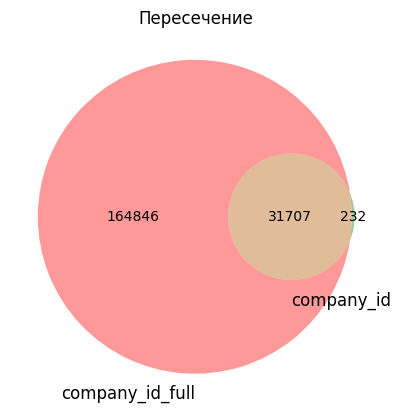

In [ ]:
# Сравнение наборы значений с помощью диаграммы Венна
first_id = set(company_and_rounds_df['company_id_full'].dropna().unique())
second_id = set(company_and_rounds_df['company_id'].dropna().unique())

# Строим диаграмму Венна
venn2([first_id, second_id], set_labels=('company_id_full', 'company_id'))

# Отображаем график
plt.title('Пересечение')
plt.show()

Исходя из диаграммы Венна, можно сделать следующие выводы. Поле `company_id_full` содержит 164846 уникальных идентификаторов компаний. Практически все уникальные идентификаторы из `company_id` (31707) присутствуют в `company_id_full`. Есть 232 уникальных идентификатора, которые присутствуют только в `company_id` и отсутствуют в `company_id_full`.<br>
Далее проверим значения построчно - совпадают ли id в каждой конкретной строке.


In [ ]:
# Создаем копию датафрейма только с company_id_full и company_id, без пропусков хотя бы в одном из них
temp_df = company_and_rounds_df[['company_id_full', 'company_id']].dropna(subset=['company_id_full', 'company_id'], how='any')

# Проводим построчное сравнение
comparison_result = temp_df['company_id_full'] == temp_df['company_id']

# Выводим результат
print('Результат построчного сравнения company_id_full и company_id:')
print(f'Всего строк для сравнения: {len(comparison_result)}')
print(f'Количество строк, где значения совпадают: {comparison_result.sum()}')
print(f'Количество строк, где значения отличаются: {len(comparison_result) - comparison_result.sum()}')
print(f'Процент совпадений: {comparison_result.mean().round(2)}')



Результат построчного сравнения company_id_full и company_id:
Всего строк для сравнения: 52626
Количество строк, где значения совпадают: 52626
Количество строк, где значения отличаются: 0
Процент совпадений: 1.0


Можно сделать вывод, что `company_id_full` — это полный справочник компаний (196553 уникальных id, часть из которых встречаются в датасете больше одного раза), а `company_id` — это узкая выборка только тех компаний, которые привлекали инвестиции (31939 уникальных id). Построчное сравнение показало, что в 52626 (24%) строках в обоих столбцах id совпадает. В остальных случаях совпадения нет, но это вызвано не расхождениями, а тем, что в одном из столбцов стоит пропуск. Таким образом, для корректной связи таблиц необходимо использовать company_id_full в качестве основного ключа, а company_id — применять для фильтрации подмножества компаний с инвестициями.

В конце проверим полные и неполные дубликаты в датафрейме `company_and_rounds_df`. Неполные дубликаты проверим по столбцам `company_id` и `funding_round_id`, чтобы исключить повторы информации по раундам финансирования для одной и той же компании.

In [ ]:
# Проверяем полные дубликаты в датафрейме company_and_rounds_df
company_and_rounds_df.duplicated().sum()

np.int64(0)

In [ ]:
# Проверяем неполные дубликаты в датафрейме company_and_rounds_df одновременно по столбцам
# company  id' и funding  round  id, предварительно с помощью метода dropna() отфильтруем пропуски,
# иначе в резульатат попадут стороки, где id компании и id райна есть пропуски (NaN)
company_and_rounds_df.dropna(subset=['company_id', 'funding_round_id']).duplicated(subset=['company_id', 'funding_round_id']).sum()

np.int64(0)

Информация по id компании и id финансового раунда не дублируется.

Обратимся к данным датасета `datasets/people.csv`, который содержит информацию о сотрудниках.

In [ ]:
# Выводим первые строки датафрейма people_df

print(
    '''
датафрейм people_df

cодержит информацию о сотрудниках:
id — идентификатор сотрудника.
first_name — имя сотрудника.
last_name — фамилия сотрудника.
company_id — идентификатор компании.
network_username — ник в социальных сетях.
'''
)

display(people_df.head(10))


датафрейм people_df

cодержит информацию о сотрудниках:
id — идентификатор сотрудника.
first_name — имя сотрудника.
last_name — фамилия сотрудника.
company_id — идентификатор компании.
network_username — ник в социальных сетях.



,id,first_name,last_name,company_id,network_username
0,10,Mark,Zuckerberg,5.0,NaN
1,100,Peter,Lester,27.0,NaN
2,1000,Dr. Steven,E. Saunders,292.0,NaN
3,10000,Neil,Capel,2526.0,NaN
4,100000,Sue,Pilsch,NaN,NaN
5,100002,Keith,Kurzendoerfer,NaN,NaN
6,100006,Courtney,Homer,81558.0,jobsbostontech
7,100009,Eddy,Badrina,NaN,NaN
8,100010,Michael,Dadashyan,NaN,fbroulette
9,100011,Jeff,Grell,NaN,NaN


In [ ]:
# Выводим информацию о датафрейме people_df
people_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226709 entries, 0 to 226708
Data columns (total 5 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                226709 non-null  int64  
 1   first_name        226700 non-null  object 
 2   last_name         226705 non-null  object 
 3   company_id        34615 non-null   float64
 4   network_username  38867 non-null   object 
dtypes: float64(1), int64(1), object(3)
memory usage: 8.6+ MB


In [ ]:
# Отобразим статистику по количеству и доле пропусков в датафрейме  people_df

show_missing_stats(people_df)

,Кол-во пропусков,Доля пропусков
first_name,9,0.000000
last_name,4,0.000000
company_id,192094,0.847300
network_username,187842,0.828600


Датасет `datasets/people.csv` содержит 226709 строк и 5 столбцов, в которых представлена информация о сотрудниках компаний (стартапов).

После первичного знакомства с данными можно сказаит следующие:

- **Оформление названия столбцов**: оформление названий столбцов соответствует виду `snake case`.

- **Название и содержание столбцов**: ключевое поле, по которому можно объединить датасет `people_df` и `company_and_rounds_df` — это `company_id`.  <br> Обращает на себя внимание столбец `network_username` — это ник в социальной сети. В данном случае имеется в виду ник сотрудника в социальной сети, потому что никнеймы часто включают в себя имена и фамилии сотрудников. Отметим, что в датасете `company_and_rounds_df` также есть поле `network username`, но оно созержит никней компании. Таким образом, эти поля отличаются. В остальном названия столбцов соответствуют описанию.

- **Пропуски**: пропуски содержатся во всех столбцах, кроме id сотрудника, но их количество варьируется. Самое большое количество пропусков в столбцах с индентификатором компании `company_id` — их 192094, что составляет 84,7% от всех данных, и в столбце со сведениями о нике сотрудников в социальных сетях — таковых 187842, что составляет 82,8%. Незначительное количество пропусков 5 и 1 содержатся в столбцах с именами и фамилиями сотрудников `first_name` и `last_name`.

- **Типы данных**: данные в столбцах представлены тремя типами данных: `object`, `float64` и `int64`. Типы соответствуют содержанию столбцов. У числовых столбцов `id` и `company_id` можно понизить разрядность.

Проверим идентификаторы сотрудников и компаний на нулевые значения.

In [ ]:
# Отобразим информацию количестве нулевых значений в столбцах id и company_id
columns_to_check = ['id', 'company_id']
print_non_zero_values(people_df, columns_to_check)

Размер датафрейма: 226709

Количество значений без пропусков (NaN) в id:  226709
Количество значений 0 в id:  0
Количество значений без пропусков (NaN) и без 0 в id:  226709
--------------------------------------------------------------------------------
Количество значений без пропусков (NaN) в company_id:  34615
Количество значений 0 в company_id:  0
Количество значений без пропусков (NaN) и без 0 в company_id:  34615
--------------------------------------------------------------------------------


Нулевых значений в столбцах `id` и `company_id` не обнаружено.
Проверим дальше количество уникальных значений в этих столбцах.

In [ ]:
# Отобразим количество уникальных занчений в столбцах id, company_id и network_username
columns_to_check = ['id', 'company_id', 'network_username']
print_count_uniq_values(people_df, columns_to_check)

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 226709

Количество уникальных значений в id: 226708
Количество уникальных значений в company_id: 22922
Количество уникальных значений в network_username: 38421


В столбце с идентификатором сотрудника `id` одно значение встречается дважды. Получается количество уникальных id сотрудников составило 226708. <br>

По id компании  `company_id` мы обнаружили следуюшее: <br>
идентификаторов компаний: 34615 <br>
уникальных идентификаторов компаний: 22922 <br>
Если сравнить с данными из датасета `company_and_rounds_df`, то:<br>
идентификаторов компаний: 52928<br>
уникальных идентификаторов компаний: 31939<br>

Сравнение показывает, что не для всех компаний есть информация о сотрудниках.

Далее проверим наличие в датафрейме полных и неполных дубликатов. Неполные дубликаты будем смотреть по полям `first_name`, `last_name`, `company_id`.

In [ ]:
# Проверяем явные дубликаты в датафрейме people_df
people_df.duplicated().sum()

np.int64(0)

In [ ]:
# Проверяем наличие неявных дубликатов одновременно по first_name, last_name и company_id
people_df.dropna(subset=['first_name', 'last_name', 'company_id']).duplicated(subset=['first_name', 'last_name', 'company_id']).sum()



np.int64(22)

In [ ]:
# Выведем на экран дубликаты по first_name, last_name и company_id
people_df.dropna(subset=['first_name', 'last_name', 'company_id']).loc[
    people_df.dropna(subset=['first_name', 'last_name', 'company_id']).
    duplicated(subset=['first_name', 'last_name', 'company_id'], keep=False)]



,id,first_name,last_name,company_id,network_username
857,101082,Chris,O'Neill,269014.0,croneill
11930,115124,Xavier,Orduña,140564.0,xorduna
12552,115856,Xavier,Orduña,140564.0,xorduna
14806,118504,Joaquin,Saez,143521.0,NaN
22852,128448,Joaquin,Saez,143521.0,NaN
27616,134961,Anthony,Lin,5910.0,NaN
41144,151908,Maria,Disla,81241.0,xmariacrisx
41760,15257,James,Wong,8647.0,NaN
41769,15258,Tim,Nguyen,8647.0,NaN
42422,15327,Tim,Nguyen,8647.0,NaN


В датасете `people_df` встречаются 22 неполных дубликата по столбцам с именем, фамилией и id компании: `first_name`, `last_name` и `company_id`. В большинстве случаях `network_username` тоже повторяются. Явных дубликатов нет.
    
Перейдем к знакомству с датасетом `datasets/education.csv`.

In [ ]:
# Выводим информацию о датафрейме education_df
education_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109610 entries, 0 to 109609
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            109610 non-null  int64 
 1   person_id     109610 non-null  int64 
 2   instituition  109555 non-null  object
 3   graduated_at  58054 non-null   object
dtypes: int64(2), object(2)
memory usage: 3.3+ MB


In [ ]:
# Выводим первые строки датафрейма educatione_df

print(
    '''
датафрейм educatione_df

содержит информацию об образовании сотрудника:
id — идентификатор записи об образовании.
person_id — идентификатор работника.
instituition — название учебного заведения.
graduated_at — дата получения образования.
'''
)

display(education_df.head(10))


датафрейм educatione_df

содержит информацию об образовании сотрудника:
id — идентификатор записи об образовании.
person_id — идентификатор работника.
instituition — название учебного заведения.
graduated_at — дата получения образования.



,id,person_id,instituition,graduated_at
0,1,6117,NaN,NaN
1,2,6136,"Washington University, St. Louis",1990-01-01
2,3,6136,Boston University,1992-01-01
3,4,6005,University of Greenwich,2006-01-01
4,5,5832,Rice University,NaN
5,6,1017,Northeastern University,1988-01-01
6,7,6176,Rochester Institute of Technology,2002-01-01
7,8,5412,University of Cambridge,2002-01-01
8,9,1243,University of Oregon,1997-01-01
9,10,6265,University of Pennsylvania,1989-01-01


In [ ]:
# Выводим информацию о датафрейме education_df
education_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109610 entries, 0 to 109609
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            109610 non-null  int64 
 1   person_id     109610 non-null  int64 
 2   instituition  109555 non-null  object
 3   graduated_at  58054 non-null   object
dtypes: int64(2), object(2)
memory usage: 3.3+ MB


In [ ]:
# Отобразим статистику по количеству и доле пропусков в датафрейме education_df

show_missing_stats(education_df)

,Кол-во пропусков,Доля пропусков
instituition,55,0.000500
graduated_at,51556,0.470400


Датасет `datasets/education.csv` содержит 109610 строк и 4 столбца, в которых представлена информация об образовании сотрудника. Столько же строк содержит датафрейм `education_df`

После первичного знакомства с данными можно сказаит следующие:

- **Оформление названия столбцов**: оформление названий столбцов соответствует виду `snake case`.

- **Название и содержание столбцов**: названия столбцов соответсуют их содержанию.  

- **Пропуски**: пропуски содержатся в двух столбцах. В столбце `instituition` всего 55 пропусков, в `graduated_at` 51556 пропусков, что составляет 47% от всех данных в этом столбце.  

- **Типы данных**: данные в столбцах представлены тремя типами данных: `object` и `int64`. Типы соответствуют содержанию столбцов. Можно понизать раздядность у столбцов с числовыми типами данных: `id` и `person_id`.

Проверим идентификаторы сотрудников на наличие нулевых и уникальных значений.

In [ ]:
# Отобразим информацию количестве нулевых значений в столбцах id и person_id
columns_to_check = ['id', 'person_id']
print_non_zero_values(education_df, columns_to_check)

Размер датафрейма: 109610

Количество значений без пропусков (NaN) в id:  109610
Количество значений 0 в id:  0
Количество значений без пропусков (NaN) и без 0 в id:  109610
--------------------------------------------------------------------------------
Количество значений без пропусков (NaN) в person_id:  109610
Количество значений 0 в person_id:  0
Количество значений без пропусков (NaN) и без 0 в person_id:  109610
--------------------------------------------------------------------------------


В столбцах `id` и `person_id` нет нулевых значений. Количество идентификаторов сотрудников в датафрейме `education_df` составило 109610, что практически вдвое меньше количества идентификаторов сотрудников в датафрейме `people_df` — 226709.

In [ ]:
# Отобразим количество уникальных занчений в столбцах id и person_id
print_count_uniq_values(education_df, columns_to_check)

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 109610

Количество уникальных значений в id: 109610
Количество уникальных значений в person_id: 68451


Обнаружены повторы в столбце `person_id` — то есть идентификатор сотрудника встречается в датафрейме более одного раза. При этом все идентификаторы образования в столбце id уникальны. Это может указывать на наличие дубликатов или на то, что сотрудники закончили несколько учебных заведений.

Проверим датафрейм на наличие явных и неявных дубликатов.

In [ ]:
# Проверяем явные дубликаты в датафрейме education_df
education_df.duplicated().sum()

np.int64(0)

In [ ]:
# Проверяем неявные дубликаты одновременно по person_id и instituition
education_df.dropna(subset=['person_id', 'instituition']).duplicated(subset=['person_id', 'instituition']).sum()

np.int64(6916)

In [ ]:
# Проверяем неявные дубликаты одновременно по person_id, instituition и graduated_at
education_df.dropna(subset=['person_id', 'instituition', 'graduated_at']).duplicated(subset=['person_id', 'instituition', 'graduated_at']).sum()

np.int64(912)

Датафрейм `education_df` не содержитс явных дубликатов, однако есть 6919 строк, в которых совпадает id сотрудника и название учебного заведения, который он заканчивал, и 912 строк с идентичными значениями по id сотрудника, названию учебного заведения и датой окончания. При этом пропуски в этих полях были предварительно исключены. Вероятно, что совпадения значений одновременно по трем столбцам  `person_id`, `instituition` и `graduated_at` указывает на то, что это неполные дубликаты.

Познакомимся с датасетом `datasets/education.csv`.

In [ ]:
# Выводим первые строки датафрейма degrees_df

print(
    '''
датафрейм degrees_df

содержит информацию о типе образования сотрудника:
id — идентификатор записи.
object_id — идентификатор сотрудника.
degree_type — тип образования.
subject — специальность.
'''
)

display(degrees_df.head(10))


датафрейм degrees_df

содержит информацию о типе образования сотрудника:
id — идентификатор записи.
object_id — идентификатор сотрудника.
degree_type — тип образования.
subject — специальность.



,id,object_id,degree_type,subject
0,1,p:6117,MBA,NaN
1,2,p:6136,BA,"English, French"
2,3,p:6136,MS,Mass Communication
3,4,p:6005,MS,Internet Technology
4,5,p:5832,BCS,"Computer Science, Psychology"
5,6,p:1017,BS,Computer Science
6,7,p:6176,BS,Computer Science
7,8,p:5412,MS,Politics
8,9,p:1243,BA,International Business & Marketing
9,10,p:6265,BS,Economics


In [ ]:
# Выводим информацию о датафрейме degrees_df
degrees_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109610 entries, 0 to 109609
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   id           109610 non-null  int64 
 1   object_id    109610 non-null  object
 2   degree_type  98389 non-null   object
 3   subject      81298 non-null   object
dtypes: int64(1), object(3)
memory usage: 3.3+ MB


In [ ]:
# Отобразим статистику по количеству и доле пропусков в датафрейме degrees_df

show_missing_stats(degrees_df)

,Кол-во пропусков,Доля пропусков
degree_type,11221,0.102400
subject,28312,0.258300


Датасет `datasets/degrees.csv` содержит 109610 строк и 4 столбца, в которых представлена информация о типе образования сотрудника.

После первичного знакомства с данными можно обозначить следующие:

- **Оформление названия столбцов**: оформление названий столбцов соответствует виду `snake case`.

- **Название и содержание столбцов**: названия столбцов соответсуют их содержанию. Стоит обратить внимание на то, что id сотрудника в этом датасете хранится в виде буквы "p", значка ":" и числа. В других датасетах id сотрудников представлено в виде числа.

- **Пропуски**: пропуски содержатся в двух столбцах. В столбце `degree_type`  11218 пропусков (10.25), в `subject` 28312 пропусков, что составляет 25.8% от всех данных в этом столбце.

- **Типы данных**: данные в столбцах представлены тремя типами данных: `object` и `int64`. В отличии от других датасетов, id сотрудника здесь имеет тип данных `object`, а не `int64`. Типы соответствуют содержанию столбцов. Можно понимать разрядность в столбеце `id` с типом данных `int64`.

Проверим количество уникальных значений в этом датафрейме, а также количество нулевых значений в столбце `id`.

In [ ]:
# Отобразим информацию количестве нулевых значений в столбцах id
columns_to_check = ['id']
print_non_zero_values(education_df, columns_to_check)

Размер датафрейма: 109610

Количество значений без пропусков (NaN) в id:  109610
Количество значений 0 в id:  0
Количество значений без пропусков (NaN) и без 0 в id:  109610
--------------------------------------------------------------------------------


In [ ]:
# Отобразим количество уникальных занчений в датафрейме degrees_df
columns_to_check = ['id', 'object_id', 'degree_type', 'subject']
print_count_uniq_values(degrees_df, columns_to_check)


Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 109610

Количество уникальных значений в id: 109610
Количество уникальных значений в object_id: 68451
Количество уникальных значений в degree_type: 7147
Количество уникальных значений в subject: 20050


Поле с идентификатором сотрудника содержат 109610 значений, из них уникальных — 68451.
Сравним информацию по id сотрудников в трех датафреймах.

In [ ]:
print('people_df')
columns_to_check = ['id']
print_non_zero_values(people_df, columns_to_check)
print()
print_count_uniq_values(people_df, columns_to_check)
print('=' * 80)

print('education_df')
columns_to_check = ['person_id']
print_non_zero_values(education_df, columns_to_check)
print()
print_count_uniq_values(education_df, columns_to_check)
print('=' * 80)

print('degrees_df')
columns_to_check = ['object_id']
print_non_zero_values(degrees_df, columns_to_check)
print()
print_count_uniq_values(degrees_df, columns_to_check)
print('=' * 80)



people_df
Размер датафрейма: 226709

Количество значений без пропусков (NaN) в id:  226709
Количество значений 0 в id:  0
Количество значений без пропусков (NaN) и без 0 в id:  226709
--------------------------------------------------------------------------------

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 226709

Количество уникальных значений в id: 226708
education_df
Размер датафрейма: 109610

Количество значений без пропусков (NaN) в person_id:  109610
Количество значений 0 в person_id:  0
Количество значений без пропусков (NaN) и без 0 в person_id:  109610
--------------------------------------------------------------------------------

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 109610

Количество уникальных значений в person_id: 68451
degrees_df
Размер датафрейма: 109610

Количество значений без пропусков (NaN) в object_id:  109610
Количество значений 0 в object_id:  0
Количество значений без пропусков (NaN) и без 0 в obj

При сравнении полей с id сотрудника из разных датасетов видно, что количество значений с id сотрудника и количество уникальных id сотрудника совпадают в датафреймах education_df и degrees_df:
- количество значений с id сотрудника: 109610
- количество уникальных значений c id сотрудника: 68451
Значит эти два датафрейма содержат информаию об образовании одних и техже сотрудниках.

Проверим датафрейм на наличие явных и неявных дубликатов.

In [ ]:
# Проверяем явные дубликаты в датафрейме degrees_df
degrees_df.duplicated().sum()

np.int64(0)

In [ ]:
# Проверяем неявные дубликаты одновременно по object_id, degree_type
degrees_df.dropna(subset=['object_id', 'degree_type']).duplicated(subset=['object_id', 'degree_type']).sum()

np.int64(2265)

Обнаружено 2256 повторов по значиям в полях с id сотдуника и типом образования. Однако сотрудника мог получить две степени на одном и томже уровне образования. Проверим этот момент и выведем количество дибликатов одновременно по трем полям.

In [ ]:
# Проверяем неявные дубликаты одновременно по object_id, degree_type, subject
degrees_df.dropna(subset=['object_id', 'degree_type','subject']).duplicated(subset=['object_id', 'degree_type', 'subject']).sum()

np.int64(468)

In [ ]:
# Выведем строки с неполными дубликатами
degrees_df.dropna(subset=['object_id', 'degree_type', 'subject']).loc[
    degrees_df.dropna(subset=['object_id', 'degree_type', 'subject']).duplicated(subset=[
        'object_id', 'degree_type', 'subject'], keep=False)].sort_values('object_id', ascending=False)


,id,object_id,degree_type,subject
14320,14321,p:99386,PhD,Computer Science
14321,14322,p:99386,PhD,Computer Science
35834,35835,p:98819,Degree,Degree
35835,35836,p:98819,Degree,Degree
608,609,p:9759,MS,Computer Science
609,610,p:9759,MS,Computer Science
17196,17197,p:96723,MS,Computer science
17195,17196,p:96723,MS,Computer science
31421,31422,p:9667,Degree,Degree
31420,31421,p:9667,Degree,Degree


Как можно увидеть, в датафрейме есть 468 дубликтов, в которых совпадают значения по id сотрудника, типом образования и специальностью. Такие значения можно определить как неполные дубликаты.

Заметим, что при первичном знакомстве с датафреймом education_df мы обнарудили, что 912 строк имеют идентичными значениями по id сотрудника, названию учебного заведения и дате окончания. Теперь понятно, что сотрудник мог получить более одной специальности по завершению обучения.

**Промежуточный вывод:** <br>

**Датафрейм `acquisition_df`: 9407 строк и 6 столбцов** <br>
1) Значительное количество **пропусков** 7579 или 80.5%  содержатся в столцах `term_code` с информацией о вариантах расчёта и небольшое количество пропусков в `acquired_at`. В столбце `price_amount` встрачаются пропущенные значения, обозначенные как 0.<br>
2) Все **индентификаторы сделок** уникальны: каждая строка — это уникальное событие покупки. 4793 уникальных покупателя в столбе `acquiring_company_id` указывает на то, что часть компании совершила несколько покупок. Заметим также, что в небольшая часть компаний (стартапов) в столбце `acquired_company_id` встречается не один раз — это говорит о том, что эти компании были куплены более одного раза.<br>
3) **Явных дубликатов** нет. По столбцам acquiring_company_id и acquired_company_id встречается 25 **неявных дубликатов**: то есть данные о приобретении компанией одного и того же стартапа больше одного раза.<br>
4) Столбец `acquired_at` с типом данных object содержит сведения о дате сделки. Его нужно будет **преобразовать** к типу datetime64. Можно также понизить разрядность числовых данных в столбцах с индентификатором сделки и компаний: `id`, `acquiring_company_id`, `acquired_company_id`.<br>

**Датафрейм `company_and_rounds_df`: 217774 строки и 22 столбца** <br>
1) **Ключевые столбец:** в датасете — это два столбца с идентификатором компании. По этим столбцам можно объядинить этот датафрейм с датафреймом `acquisition_df`. Столбец `company_id_full` с 217472 значениями без пропусков и `company_id`c 52928 значениями без пропусков (из них 31939 уникальные). При этом `company_id_full` содержит 0.1% пропусков, а в `company_id` 75.7%. Мы предполагает, что этот датасет возник благодаря объединению двух таблиц по идентификатору id компании (с типом объединеия full или outer, который предполагает включение всех строк из обоих датафреймов и заполнение отсутствующие значения). Заметно, что одна таблица несла скорее общую информацию о компаниях, а другая информацию о финансовых раундах. Есть также столбец с ником компании в сети `network_username`, который содержит больше уникальных значений (79571), чем в `company_id`.<br>
2) В датасете 217774 строки, **пропуски** содержатся во всех столбцах, но их количество варьируется. Также отметим, что хотя в столбцах `investment  rounds`, `funding  rounds`, `funding  total`, `milestones` есть незначительное число пропусков, в них также встречаются значения 0.
3) Во многих столбцах, имеющих числовой тип данных, помимо пропусков, еще есть **нулевые значения**.<br>
4) **Явных дубликатов** в датафрейме нет. Также нет **неполных дубликатов** одновременно по id компании и id раунда финансирования.
5) **Названия столбцов** были приведены к виду `snake case`.<br>
6) Столбцы `founded  at`, `closed  at`, `funded  at` с информацией о датах имеют **тип данных** `object`, их нужно будет **преобразовать** к типу datetime64. В столбцах с типом данных `float64` `milestones`, `funding round id`, `company id`, `participants`, `is first round`, `is last round` необходимо будет понизить разрядность.<br>


**Датафрейм `people_df`: 226709 строк и 5 столбцов** <br>
1) Датасеты `people_df` и `company_and_rounds_df` можно **объединить** по столбцу `company_id`. Обращает на себя внимание столбец `network_username` — это ник в социальной сети. В данном случае это ник сотрудника в социальной сети. В датасете `company_and_rounds_df` также есть поле `network username`, но оно созержит никней компании.<br>
2) **Пропуски** содержатся во всех столбцах, кроме id сотрудника, но их количество сильно варьируется. <br>
3) Сравнение с полем c id компании из датафрейма `company_and_rounds_df` показывает, что не для всех компаний есть информация о сотрудниках.
4) В датасете `people_df` встречаются 22 неполных **дубликата** по столбцам с именем, фамилией и id компании: `first_name`, `last_name` и `company_id`. В большинстве случаях `network_username` тоже повторяются. Явных дубликатов нет.
5) Данные в столбцах представлены тремя **типами данных**: `object`, `float64` и `int64`. Типы соответствуют содержанию столбцов. У числовых столбцов `id` и `company_id` можно понизить разрядность.<br>


**Датафрейм `education_df`: 109610 строк и 4 столбца** <br>
1) **Пропуски** содержатся в двух столбцах: в столбце `instituition` 55 пропусков, в `graduated_at` 51556 пропусков, что составляет 47% от всех данных в этом столбце.<br>
2) В столбцах `id` и `person_id` нет нулевых значений. Количество идентификаторов сотрудников в датафрейме `education_df` составило 109610, что практически вдвое меньше количества идентификаторов сотрудников в датафрейме `people_df` — 226709.<br>
3) Датафрейм `education_df` не содержитс явных дубликатов, однако есть 6919 строк, в которых совпадает id сотрудника и название учебного заведения, который он заканчивал, и 912 строк с идентичными значениями по id сотрудника, названию учебного заведения и датой окончания.<br>
4) Данные в столбцах представлены тремя **типами данных**: `object` и `int64`. Типы соответствуют содержанию столбцов. Можно понизать раздядность у столбцов с числовыми типами данных: `id` и `person_id`.<br>


**Датафрейм `degrees_df`: 109610 строк и 4 столбца** <br>
1) **Пропуски** содержатся в двух столбцах. В столбце `degree_type`  11218 пропусков (10.25%), в `subject` 28312 пропусков, что составляет 25.8% от всех данных в этом столбце.<br>
2) Данные в столбцах представлены тремя **типами данных**: `object` и `int64`. В отличии от других датасетов, id сотрудника здесь имеет тип данных `object`, а не `int64`. Типы соответствуют содержанию столбцов. Можно понимать разрядность в столбеце `id` с типом данных `int64`.<br>
3) В датафрейме есть 468  **неполных дубликтов**, в которых совпадают значения по id сотрудника, типом образования и специальностью. Такие значения можно определить как неполные дубликаты.<br>



### 1.2. Смена типов и анализ пропусков

- Обработаем типы данных в столбцах, которые хранят значения даты и времени, если это необходимо.
- Оценим полноту данных — сделаем предварительный вывод, достаточно ли данных для решения задач проекта.

Теперь преобразуем столбцы, которые хранят значения даты и времени, к типу `datetime64`. Сделаем это для всех датафреймов.
А после перейдем к финальному анализу пропусков.


In [ ]:
# Преобразуем данные с датой и временем founded_at, closed_at, funded_at
# из датафрейма company_and_rounds_df к типу datetime64 с помощью метода to_datetime,
# Создадим список столбцов для преобразования
columns_to_convert = ['founded_at', 'closed_at', 'funded_at']

for column in columns_to_convert:
    company_and_rounds_df[column] = pd.to_datetime(company_and_rounds_df[column])


In [ ]:
# Проверяем тип данных после преобразования
company_and_rounds_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217774 entries, 0 to 217773
Data columns (total 22 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   company_id_full      217472 non-null  float64       
 1   name                 217471 non-null  object        
 2   category_code        143886 non-null  object        
 3   status               217472 non-null  object        
 4   founded_at           109956 non-null  datetime64[ns]
 5   closed_at            3449 non-null    datetime64[ns]
 6   domain               147159 non-null  object        
 7   network_username     95534 non-null   object        
 8   country_code         108607 non-null  object        
 9   investment_rounds    217472 non-null  float64       
 10  funding_rounds       217472 non-null  float64       
 11  funding_total        217472 non-null  float64       
 12  milestones           217472 non-null  float64       
 13  funding_round_

In [ ]:
# Преобразуем данные с датой и временем acquired_at
# из датафрейма acquisition_df к типу datetime64

acquisition_df['acquired_at'] = pd.to_datetime(acquisition_df['acquired_at'])

In [ ]:
# Проверяем тип данных после преобразования
acquisition_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9407 entries, 0 to 9406
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id                    9407 non-null   int64         
 1   acquiring_company_id  9407 non-null   int64         
 2   acquired_company_id   9407 non-null   int64         
 3   term_code             1831 non-null   object        
 4   price_amount          9407 non-null   int64         
 5   acquired_at           9378 non-null   datetime64[ns]
dtypes: datetime64[ns](1), int64(4), object(1)
memory usage: 441.1+ KB


In [ ]:
# Преобразуем данные с датой и временем graduated_at
# из датафрейма education_df к типу datetime64.
# Поскольку в этом столбце все даты начинаются с первого числа месяца,
# c помощью параметра format пропишем шаблон с форматом, в котором хранятся данные: год-месяц-день

education_df['graduated_at'] = pd.to_datetime(education_df['graduated_at'], format='%Y-%m-%d')

In [ ]:
# Проверяем тип данных после преобразования
education_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109610 entries, 0 to 109609
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            109610 non-null  int64         
 1   person_id     109610 non-null  int64         
 2   instituition  109555 non-null  object        
 3   graduated_at  58054 non-null   datetime64[ns]
dtypes: datetime64[ns](1), int64(2), object(1)
memory usage: 3.3+ MB


In [ ]:
# Выведем на экран первые строки, чтобы проверить корректность формата даты
education_df.head(10)

,id,person_id,instituition,graduated_at
0,1,6117,NaN,NaT
1,2,6136,"Washington University, St. Louis",1990-01-01
2,3,6136,Boston University,1992-01-01
3,4,6005,University of Greenwich,2006-01-01
4,5,5832,Rice University,NaT
5,6,1017,Northeastern University,1988-01-01
6,7,6176,Rochester Institute of Technology,2002-01-01
7,8,5412,University of Cambridge,2002-01-01
8,9,1243,University of Oregon,1997-01-01
9,10,6265,University of Pennsylvania,1989-01-01


Мы выполнили преобразование типов данных в столбцах, содержащих даты и время (founded_at, closed_at, funded_at, acquired_at, graduated_at). Теперь они приведены к формату datetime64, что позволит удобно выполнять группировки по годам, анализировать временные промежутки и строить динамику показателей.

Для предварительного вывода о том, достаточно ли данных для решения задач необходимо оценить полноту данных в полях, которые критичны для последующего анализа. Предварительный анализ этого вопроса мы сделали на предыдущем шаге. На этом этапе сведем информацию вместе с помощью функции.


In [ ]:
# Создадим функцию, на выходе которой будет сводная таблица со статистикой
# по заполнености выбранных столбцов в датафрейме
def check_fillness(df, columns):
    """
    Анализ заполненности выбранных столбцов в датафрейме.
    Возвращает таблицу со сводной статистикой.
    """
    stats = []

    for col in columns:
        total = len(df) # считаем размер датафрейма (столбцов)
        unique = df[col].nunique(dropna=True) # выводим число уникальных элементов в столбце без пропусков
        na_count = df[col].isna().sum() # выводим количество пропусков
        zero_count = (df[col] == 0).sum() # считаем количество нулей в столбце
        not_zero_not_na = total - na_count - zero_count # считаем количество значений без пропусков и без нулей
        fillness = (not_zero_not_na / total) * 100 # вычисляем процент заполненности

        stats.append({
            "Столбец": col,
            "Всего значений": total,
            "Уникальных": unique,
            "Пропусков": na_count,
            "Нулей": zero_count,
            "Не NaN и ≠ 0": not_zero_not_na,
            "Заполненность (%)": round(fillness, 1)
        })

    return pd.DataFrame(stats)


In [ ]:
# Выведем статистику заполненности по всем датафреймам
columns_to_check = ['id', 'acquiring_company_id', 'acquired_company_id', 'price_amount']
print('acquisition_df: информация о покупках одними компаниями других компаний')
display(check_fillness(acquisition_df, columns_to_check))

columns_to_check = ['company_id_full', 'company_id', 'funding_round_id', 'raised_amount', 'funding_total', 'investment_rounds', 'funding_rounds']
print('company_and_rounds_df: информация о компаниях и раундах финансирования')
display(check_fillness(company_and_rounds_df, columns_to_check))

columns_to_check = ['id', 'first_name', 'last_name', 'company_id']
print('people_df: информация о сотрудниках')
display(check_fillness(people_df, columns_to_check))

columns_to_check = ['person_id', 'instituition', 'graduated_at']
print('education_df: информация об образовании сотрудника:')
display(check_fillness(education_df, columns_to_check))

columns_to_check = ['object_id', 'degree_type', 'subject']
print('degrees_df: информация об образовании сотрудника:')
display(check_fillness(degrees_df, columns_to_check))

acquisition_df: информация о покупках одними компаниями других компаний


,Столбец,Всего значений,Уникальных,Пропусков,Нулей,Не NaN и ≠ 0,Заполненность (%)
0,id,9406,9406,0,0,9406,100.0
1,acquiring_company_id,9406,4793,0,0,9406,100.0
2,acquired_company_id,9406,9264,0,0,9406,100.0
3,price_amount,9406,1037,0,6930,2476,26.3


company_and_rounds_df: информация о компаниях и раундах финансирования


,Столбец,Всего значений,Уникальных,Пропусков,Нулей,Не NaN и ≠ 0,Заполненность (%)
0,company_id_full,217774,196553,302,0,217472,99.9
1,company_id,217774,31939,164846,0,52928,24.3
2,funding_round_id,217774,52928,164846,0,52928,24.3
3,raised_amount,217774,10266,164846,6000,46928,21.5
4,funding_total,217774,9483,302,169059,48413,22.2
5,investment_rounds,217774,42,302,214644,2828,1.3
6,funding_rounds,217774,16,302,164846,52626,24.2


people_df: информация о сотрудниках


,Столбец,Всего значений,Уникальных,Пропусков,Нулей,Не NaN и ≠ 0,Заполненность (%)
0,id,226709,226708,0,0,226709,100.0
1,first_name,226709,28421,9,0,226700,100.0
2,last_name,226709,107771,4,0,226705,100.0
3,company_id,226709,22922,192094,0,34615,15.3


education_df: информация об образовании сотрудника:


,Столбец,Всего значений,Уникальных,Пропусков,Нулей,Не NaN и ≠ 0,Заполненность (%)
0,person_id,109610,68451,0,0,109610,100.0
1,instituition,109610,21067,55,0,109555,99.9
2,graduated_at,109610,71,51556,0,58054,53.0


degrees_df: информация об образовании сотрудника:


,Столбец,Всего значений,Уникальных,Пропусков,Нулей,Не NaN и ≠ 0,Заполненность (%)
0,object_id,109610,68451,0,0,109610,100.0
1,degree_type,109610,7147,11221,0,98389,89.8
2,subject,109610,20050,28312,0,81298,74.2


**Подведем итог**<br>
`company_and_rounds_df`: есть информация о 52928 финансовых раундах, в которых участвовали 31939 компаний.<br>

`people_df`, `education_df`, `degrees_df`: для 34615 сотрудников есть информация о месте работы (компаниях) через `company_id`. Есть 109555 записей об образовании, 98392 записей о типе ообразовани, 81298 записей о специальности. Несмотря на пропуски и дублирование инфомрмации (у одно сотрудниками может быть несколько специальностей и образований), данные позволяют проводить анализ по образованию сотрудников.

`acquisition_df`: содержит данные о 9407 сделках. Информация о покупающей и продаваемой компании полностью заполнены. Сумма покупики в `price_amount` указана для 2476 записей (26.3%), остальные 6931 записей это нули, что скорее отражает отсуствтие публичной информации о сумме сделки.


Несмотря на пропуски в данных, есть сведения примерно о 50000 финансовых раундов и 31939 уникальных компаний. Ключевые идентификаторы компаний (`company_id`, `acquired_company_id`, `acquiring_company_id`) и основные числовые показатели (`funding_rounds`, `funding_total`, `price_amount`) присутствуют в данных в достаточном объёме для проведения исследования. Это же можно сказать о показателях, связанных с образованием сотрудников (`person_id`, `id`, `instituition`, `degree_type`, `subject`): можно связать данные по 34615 сотрудникам и компаниям, где они работают.

## Шаг 2. Предобработка данных, предварительное исследование


### 2.1. Раунды финансирования по годам

Составим сводную таблицу с раундами финансирования по годам. Для каждого года, по которому у нас есть данные, посчитаем:
- Типичный размер инвестиций в одном рауде.
- Общее количество раундов финансирования за этот год.
Отфильтруем результат. Оставим в итоговой таблице только те годы, для которых у нас есть информация о более чем 50 раундах.  Построим график, который наглядно покажет, как менялся типичный размер финансирования одного раунда от года к году.<br>

На основе полученных данных ответим на вопросы:

- В каком году типичный размер собранных в рамках одного раунда средств был максимален?
- Какая тенденция по количеству раундов и выделяемых в рамках каждого раунда средств наблюдалась в 2013 году?

Это задание выполняем без объединения и дополнительной предобработки на основе датасета `company_and_rounds.csv`.

Перед тем как приступить к этой задаче необходимо рассмотреть характер распределение значений в столбце `raised_amount`, в котором указана сумма финансирования. Это поможет определить, что будет являться типичным размером финансирования. Для начала используем метод describe() для вывода описательной статистики.

In [ ]:
# Изучаем статистические показатели столбца raised_amount
print("Описание распределения raised_amount:")
print(company_and_rounds_df['raised_amount'].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(3))



Описание распределения raised_amount:
count    5.292800e+04
mean     7.946092e+06
std      4.216821e+07
min      0.000000e+00
5%       0.000000e+00
25%      2.463300e+05
50%      1.600000e+06
75%      6.700000e+06
95%      2.950000e+07
99%      9.228400e+07
max      3.835050e+09
Name: raised_amount, dtype: float64


Описанительная статистика представлена в экспоненциальной (научной) нотации из-за очень больших чисел.
Среднее арифметическое значительно больше медианы: 7 946 092 и 1 600 000, что указывает на ассиметричность распределения и смещение его вправо. Построим гистограмму по данным столбца `raised_amount`.


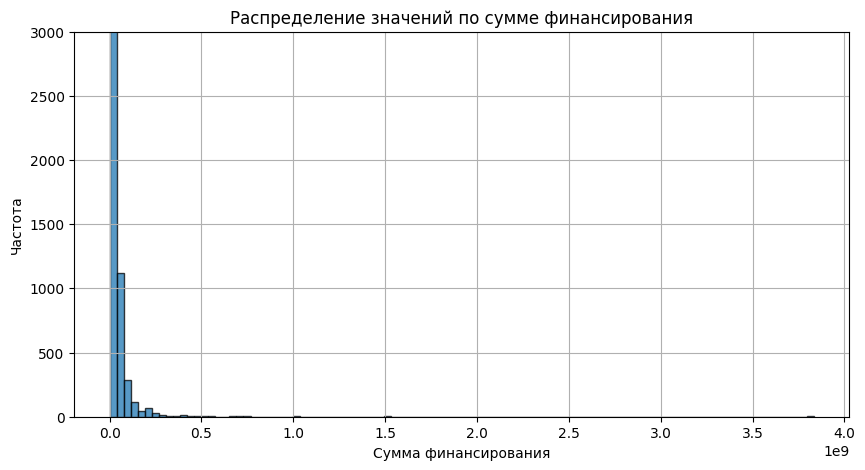

In [ ]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим гистограмму с помощью pandas через plot(kind='hist')
company_and_rounds_df['raised_amount'].plot(
                kind='hist',
                bins=100,
                alpha=0.75,
                edgecolor='black',
                rot=0,
)

# Настраиваем оформление графика
plt.title('Распределение значений по сумме финансирования')
plt.xlabel('Сумма финансирования')
plt.ylabel('Частота')
# Добавляем сетку графика
plt.grid()

plt.ylim(0, 3000)  # ограничим ось Y, чтобы убрать влияние экстремальных значений
plt.show()



Гистограмма показывает, что распределение сумм финансирования компаний асимметричное и скошено вправо. Построим диаграмму размаха для оценки выбросов и аномальных значений.

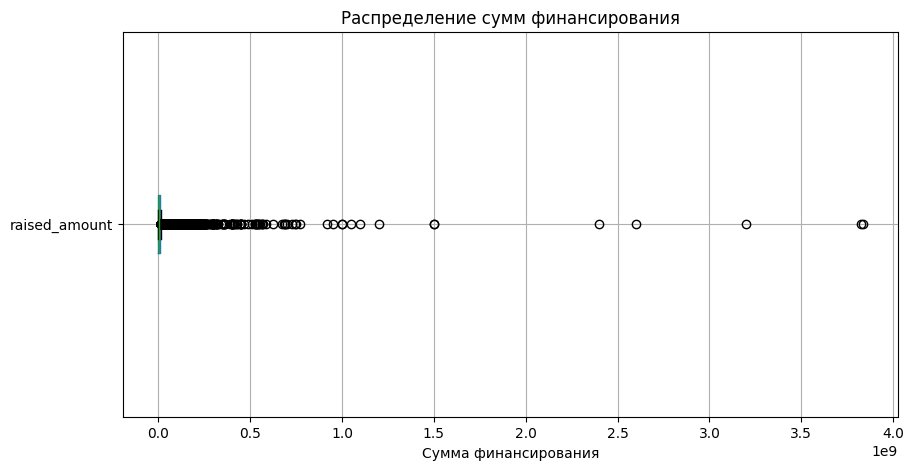

In [ ]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим диаграмму размаха значений в столбце seats
company_and_rounds_df.boxplot(column='raised_amount', vert=False)

# Добавляем заголовок и метки оси
plt.title('Распределение сумм финансирования')
plt.xlabel('Сумма финансирования')

# Выводим график
plt.show()


Диаграмма размаха демонстрирует экстримально большие значения сумм финансирования компаний. Построем диграмму размаха еще раз с параметром `showfliers=False`, чтобы увидеть основной диапазон.

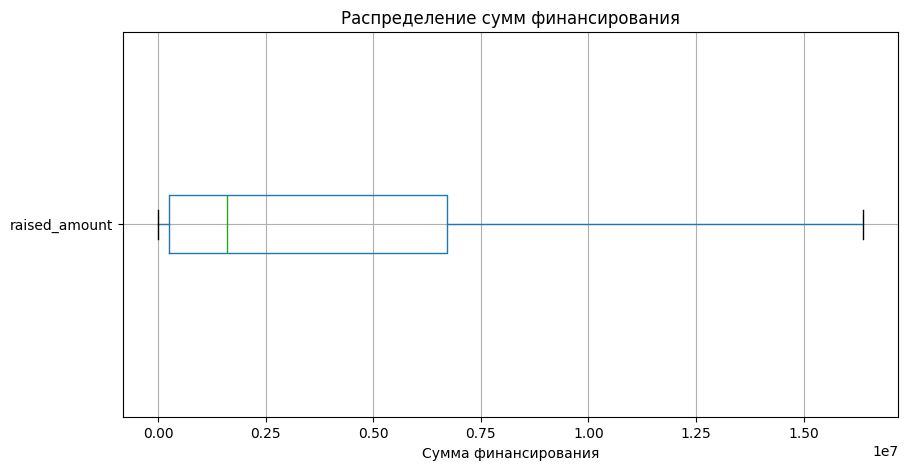

In [ ]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим диаграмму размаха значений в столбце seats
company_and_rounds_df.boxplot(column='raised_amount', vert=False, showfliers=False)

# Добавляем заголовок и метки оси
plt.title('Распределение сумм финансирования')
plt.xlabel('Сумма финансирования')

# Выводим график
plt.show()




Gоскольку распределение cумм финансирования ассимитрично и имеет выраженные выбросы, среднее не отражает реальную «середину» данных. Более надёжной характеристикой типичного значения будет медиана.<br>

Теперь составим сводную таблицу с раундами финансирования по годам.

In [ ]:
# Извлечём год из столбца funded_at и сохраним значение в новом столбце funded_year
company_and_rounds_df['funded_year'] = company_and_rounds_df['funded_at'].dt.year

# Группировка по годам - считаем медианный размер средств финансирования, средний размер средств и количество раундов
rounds_by_year = (
    company_and_rounds_df
    .groupby('funded_year')
    .agg(median_raised_amount=('raised_amount', 'median'), # типичный размер средств (медиана)
         mean_raised_amount=('raised_amount', 'mean'),     # средний размер средств
        rounds_count=('raised_amount', 'count'))           # количество раундов
    .reset_index())

# Оставляем годы, где количество раундов больше 50
rounds_by_year = rounds_by_year[rounds_by_year['rounds_count'] > 50]

# Выводим итоговую таблицу
display(rounds_by_year)



,funded_year,median_raised_amount,mean_raised_amount,rounds_count
15,1999.0,2000000.0,7.420242e+06,76
16,2000.0,4200000.0,1.148551e+07,125
17,2001.0,3000000.0,8.761519e+06,96
18,2002.0,4200000.0,7.836196e+06,116
19,2003.0,3000000.0,5.725050e+06,159
20,2004.0,5000000.0,7.593646e+06,291
21,2005.0,5500000.0,9.324877e+06,1633
22,2006.0,5000000.0,8.404267e+06,2436
23,2007.0,3973320.0,8.931094e+06,3279
24,2008.0,3110000.0,1.019180e+07,3774


Добавим экономический аспект для более корректной интерпретации тренда. Учтём инфляцию при анализе данных за разные годы, используя коэффициент дефляции, который позволяет пересчитать денежные значения в сопоставимые величины, учитывая изменение уровня цен. Предполагаем, что суммы финансирования указаны в долларах США. В качестве источника индекса потребительских цен (CPI) используем исторические данные США: RateInflation: Historical CPI USA. Ниже добавим в таблицу новый столбец с медианными значениями, пересчитанными с учётом коэффициента дефляции.

In [ ]:
#  Создадим словарь с данными CPI (индекс потребительских цен)

cpi_data = {
    1999: 166.6,
    2000: 172.2,
    2001: 177.1,
    2002: 179.9,
    2003: 184.0,
    2004: 188.9,
    2005: 195.3,
    2006: 201.6,
    2007: 207.3,
    2008: 215.3,
    2009: 214.5,
    2010: 218.1,
    2011: 224.9,
    2012: 229.6,
    2013: 233.0
}

# Приведем медианы к ценам 2013 года
median_real = []
cpi_2013 = cpi_data[2013]

for idx, row in rounds_by_year.iterrows():
    year = row['funded_year']
    nominal = row['median_raised_amount']
    real_value = nominal * cpi_2013 / cpi_data.get(year, cpi_2013)
    median_real.append(real_value)

rounds_by_year['median_real'] = median_real

# Выводим результат
display(rounds_by_year)

,funded_year,median_raised_amount,mean_raised_amount,rounds_count,median_real
15,1999.0,2000000.0,7.420242e+06,76,2.797119e+06
16,2000.0,4200000.0,1.148551e+07,125,5.682927e+06
17,2001.0,3000000.0,8.761519e+06,96,3.946923e+06
18,2002.0,4200000.0,7.836196e+06,116,5.439689e+06
19,2003.0,3000000.0,5.725050e+06,159,3.798913e+06
20,2004.0,5000000.0,7.593646e+06,291,6.167284e+06
21,2005.0,5500000.0,9.324877e+06,1633,6.561700e+06
22,2006.0,5000000.0,8.404267e+06,2436,5.778770e+06
23,2007.0,3973320.0,8.931094e+06,3279,4.465912e+06
24,2008.0,3110000.0,1.019180e+07,3774,3.365676e+06


На основе получившейся таблицы пострим график, который будет отражать динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования.

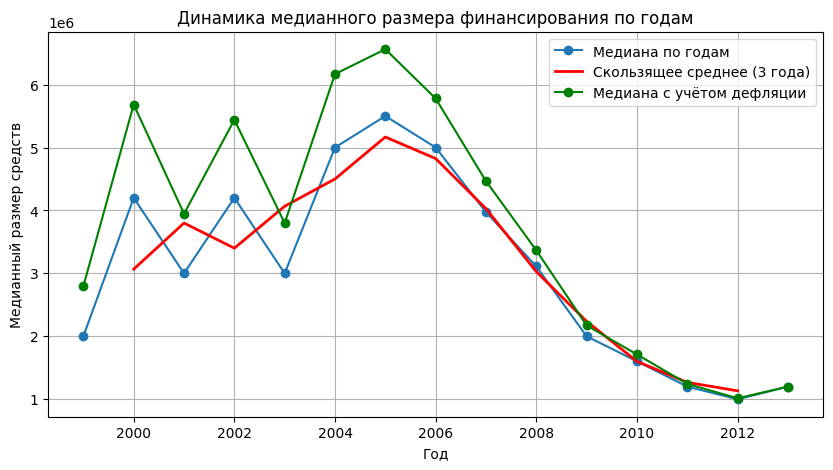

In [ ]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Добавим скользящее среднее (окно в 3 года)
rounds_by_year['median_smooth'] = rounds_by_year['median_raised_amount'].rolling(window=3, center=True).mean()

# График медианы по годам
plt.plot(rounds_by_year['funded_year'], rounds_by_year['median_raised_amount'],
         marker='o', label='Медиана по годам')

# График медианы по годам
plt.plot(rounds_by_year['funded_year'], rounds_by_year['median_smooth'],
         color='red', linewidth=2, label='Скользящее среднее (3 года)')

#  График медианы с учётом дефляции по годам
plt.plot(rounds_by_year['funded_year'], rounds_by_year['median_real'],
         marker='o', color='green', label='Медиана с учётом дефляции')

# Добавляем заголовок и метки оси
plt.title('Динамика медианного размера финансирования по годам')
plt.xlabel('Год')
plt.ylabel('Медианный размер средств')

# Включаем сетку
plt.grid(True)

# Добавляем легенду
plt.legend()

# Выводим график
plt.show()

Вернемся к вопросам:
- В каком году типичный размер собранных в рамках одного раунда средств был максимален?
- Какая тенденция по количеству раундов и выделяемых в рамках каждого раунда средств наблюдалась в 2013 году?

Максимальный типичный размер средств в рамках одного раунда финансирования наблюдается в 2005 году - 5 500 000.<br>
В 2013 году количество раундов продолжало расти по сравнению с предыдущими годами. При этом медианный размер финансирования снижался, особенно по сравнению с периодом 2004-2006 годов. Можно заключить, что рынок стартапов становился более активным: инвесторы чаще вкладывались в стартапы, но суммы финансирования в среднем стали меньше на раунд.


### 2.2. Люди и их образование

Заказчик хочет понять, зависит ли полнота сведений о сотрудниках (например, об их образовании) от размера компаний.

- Оцените, насколько информация об образовании сотрудников полна. Используя датасеты `people.csv` и `education.csv`, разделите все компании на несколько групп по количеству сотрудников и оцените среднюю долю сотрудников без информации об образовании в каждой из групп. Обоснуйте выбранные границы групп.
- Оцените, возможно ли для выполнения задания присоединить к этим таблицам ещё и таблицу `degrees.csv`.

На этом этапе необходимо:
- посмотреть, насколько информация об образовании сотрудников полна, используя датасеты `people.csv` и `education.csv`разделить компании на группы по количеству сотрудников;
- для каждой группы посчитать среднюю долю сотрудников без информации об образовании;
- обосновать выбранные границы групп;
- проверить, можно ли присоединить `degrees.csv`.

In [ ]:
# Проверим, у каких сотрудников нет информация об образовании.
# Для этого сначала объединим датафреймы people_df и education_df по столбцам id и person_id.
# Объединять будет по левому датафрейму (people_df), чтобы сохранить всю информацию по связке с компаниями
people_with_edu = people_df.merge(education_df, left_on='id',  right_on='person_id', how='left', suffixes=('_person','_edu'))



In [ ]:
# Выведим объединенный датафрейм people_with_edu
display(people_with_edu.head(10))

display(people_with_edu.info())

,id_person,first_name,last_name,company_id,network_username,id_edu,person_id,instituition,graduated_at
0,10,Mark,Zuckerberg,5.0,NaN,2415.0,10.0,Harvard University,NaT
1,100,Peter,Lester,27.0,NaN,NaN,NaN,NaN,NaT
2,1000,Dr. Steven,E. Saunders,292.0,NaN,NaN,NaN,NaN,NaT
3,10000,Neil,Capel,2526.0,NaN,NaN,NaN,NaN,NaT
4,100000,Sue,Pilsch,NaN,NaN,NaN,NaN,NaN,NaT
5,100002,Keith,Kurzendoerfer,NaN,NaN,NaN,NaN,NaN,NaT
6,100006,Courtney,Homer,81558.0,jobsbostontech,83604.0,100006.0,MIT Sloan School of Management,2004-01-01
7,100009,Eddy,Badrina,NaN,NaN,NaN,NaN,NaN,NaT
8,100010,Michael,Dadashyan,NaN,fbroulette,NaN,NaN,NaN,NaT
9,100011,Jeff,Grell,NaN,NaN,NaN,NaN,NaN,NaT


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267694 entries, 0 to 267693
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   id_person         267694 non-null  int64         
 1   first_name        267685 non-null  object        
 2   last_name         267690 non-null  object        
 3   company_id        44789 non-null   float64       
 4   network_username  50775 non-null   object        
 5   id_edu            109056 non-null  float64       
 6   person_id         109056 non-null  float64       
 7   instituition      109002 non-null  object        
 8   graduated_at      57691 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 18.4+ MB


None

Объединение датафреймов прошло успешно. Далее уберем из нового датафрейма все строки с пропусками в поле company_id, что требуется для последующего анализа.

In [ ]:
# Удаляем из датафрейма people_with_edu строки с пропусками в поле company_id
people_with_edu = people_with_edu.dropna(subset=['company_id'])
people_with_edu.reset_index(drop=True, inplace=True)

Поскольку один и тот же сотрудник может закончить более одного учебного заведения, мы уберем дубликаты по `id_person` (столбец, который был вместе с идентификаторами компаний в датафрейме `education_df`)

In [ ]:
# Убераем из датафрейма дубликаты с идентификатором сотрудника
people_with_edu.drop_duplicates(subset=['id_person'], keep='first', inplace=True)
people_with_edu.reset_index(drop=True, inplace=True)

In [ ]:
# Создаём столбец-индикатор: если у сотрудника нет записи об образовании,
# то в столбце no_education будет 1, если есть информация об образовании, то 0
people_with_edu['no_education_info'] = people_with_edu['id_edu'].isna().astype(int)


In [ ]:
# Выведим датафрейм people_with_edu, чтобы проверить корректность данных в столбце no_education
people_with_edu.sort_values(by='company_id', ascending=True).head(10)

,id_person,first_name,last_name,company_id,network_username,id_edu,person_id,instituition,graduated_at,no_education_info
20795,3,Kevin,Flaherty,1.0,NaN,706.0,3.0,Washington University in St Louis,NaT,0
783,104800,Alex,Weinstein,1.0,alexweinstein,NaN,NaN,NaN,NaT,1
34140,9729,Bharath,Balasubramanian,2.0,spinfree,594.0,9729.0,Tamilnadu College of engineering,1998-01-01,0
28154,6456,Sridhar,Vembu,3.0,NaN,43581.0,6456.0,"Indian Institute of Technology, Madras",1989-01-01,0
22924,4,Raju,Vegesna,3.0,NaN,NaN,NaN,NaN,NaT,1
25277,5,Ian,Wenig,3.0,NaN,47870.0,5.0,The Aji Network,2005-01-01,0
31234,8,Owen,Byrne,4.0,owenbyrne,1027.0,8.0,Saint Mary's (Canada),1986-01-01,0
20966,30923,Bob,Buch,4.0,bobbuch,58867.0,30923.0,"University of California, Hastings College of ...",NaT,0
33026,9,Ron,Gorodetzky,4.0,NaN,8161.0,9.0,"University of California, San Diego (UCSD)",2003-01-01,0
25691,52177,Vishwas,Prabhakara,4.0,vishwasp,5819.0,52177.0,Harvard Business School,2008-01-01,0


In [ ]:
# Посчитаем долю сотрудников без данных об образовании по каждой компании.
# Для этого создадим сводную талбицу edu_per_company
edu_per_company = people_with_edu.groupby('company_id').agg(employees_total=('id_person', 'nunique'),employees_with_edu=('no_education_info', 'sum')).reset_index()

# Вычислим долю сотрудников без образования для каждой компании
edu_per_company['share_no_edu'] = (edu_per_company['employees_with_edu'] / edu_per_company['employees_total']).round(3)




In [ ]:
# Выведим датафрейм edu_per_company, чтобы проверить корректность данных
edu_per_company.sort_values(by='employees_total', ascending=False).head(15)

,company_id,employees_total,employees_with_edu,share_no_edu
48,59.0,244,76,0.311
25,29.0,150,40,0.267
777,1242.0,138,37,0.268
20604,231067.0,72,14,0.194
378,499.0,63,20,0.317
4,5.0,61,16,0.262
1761,4175.0,56,7,0.125
376,494.0,56,20,0.357
9,12.0,51,25,0.490
248,317.0,48,7,0.146


In [ ]:
# Выведем описательную статистику по столбцу с количеством сотрудников в компании
edu_per_company['employees_total'].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

,employees_total
count,22921.000000
mean,1.510144
std,2.764379
min,1.000000
5%,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
95%,4.000000
99%,8.000000


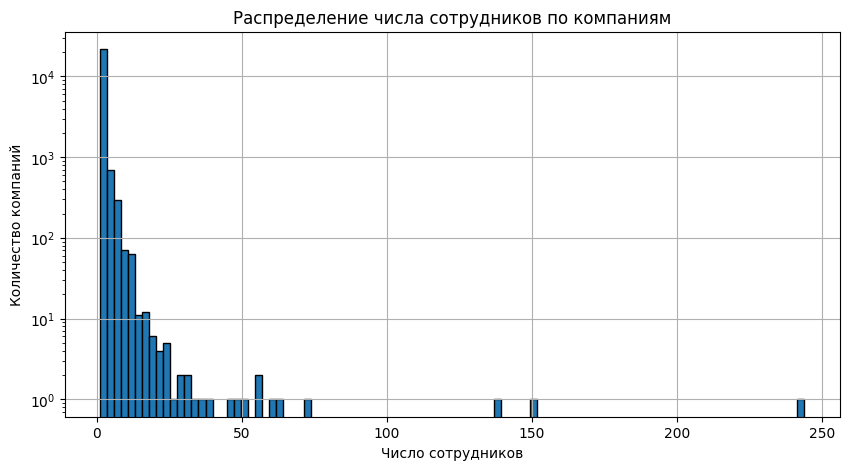

In [ ]:
# Для иллюстрации построим гистограмму распределения

# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10,5))

# Строим гистограмму с помощью pandas через plot(kind='hist')
edu_per_company['employees_total'].plot(kind='hist',
                                            bins=100,
                                            edgecolor='k')
# Настраиваем оформление графика
plt.title('Распределение числа сотрудников по компаниям')
plt.xlabel('Число сотрудников')
plt.ylabel('Количество компаний')

# Ставим логарифмическую шкалу для лучше визуализации перекошенного распределения
plt.yscale('log')  # если распределение сильно перекошено

# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()





Распределение числа сотрудников по компаниям сильно перекошено влево: почти половина компаний имеет только 1 сотрудника, а 75-й процентиль равен 1. Это делает использование квантилей для разбиения компаний на группы неинформативным — все нижние квантильные группы будут состоять почти исключительно из соло-стартапов.<br>
Поэтому более логично использовать разбиение по масштабу компании (по практическому смыслу исходя из распределения): <br> 1 сотрудник — соло-стартапы, <br> 2–5 сотрудников — малые компании, <br> 6–15 сотрудников — средние, <br> более 15 сотрудников — крупные.

In [ ]:

# Разделим компании на группы по числу сотрудников с помощью функции pd.cut():
# соло-стартапы, малые (2-5), средние (6-15), крупные (15+).
edu_per_company['company_size'] = pd.cut(edu_per_company['employees_total'],
                                         bins=[1, 2, 5, 15, edu_per_company['employees_total'].max()],
                                         labels=['соло-стартапы (1)', 'малые (2-5)', 'средние (6-15)', 'крупные (15+)'],
                                         right=False)


In [ ]:
# Посмотрим на количество компаний в группах
display(edu_per_company.groupby('company_size')['share_no_edu'].count())


/tmp/ipython-input-2789258589.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(edu_per_company.groupby('company_size')['share_no_edu'].count())


,share_no_edu
company_size,
соло-стартапы (1),18116
малые (2-5),4080
средние (6-15),676
крупные (15+),48


In [ ]:
# Считаем среднюю долю сотрудников без данных об образования по каждой группе
group_stats = (
    edu_per_company
    .groupby('company_size')['share_no_edu']
    .mean()
    .reset_index()
)

# Смотрим результат
display(group_stats)



/tmp/ipython-input-191004034.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('company_size')['share_no_edu']


,company_size,share_no_edu
0,соло-стартапы (1),0.462575
1,малые (2-5),0.472813
2,средние (6-15),0.519643
3,крупные (15+),0.393687


In [ ]:
# Проверим возможность присоединить датафрейма degrees_df

print(degrees_df[['object_id', 'degree_type', 'subject']].head())

  object_id degree_type                       subject
0    p:6117         MBA                           NaN
1    p:6136          BA               English, French
2    p:6136          MS            Mass Communication
3    p:6005          MS           Internet Technology
4    p:5832         BCS  Computer Science, Psychology


В `degrees_df` есть поле object_id, которое также содержит идентификаторы сотрудника. Отличе в том, что это поле с типом данных `object` и содержить разные символы, помимо чисел. Это необходимо будет привезти к виду, который имеют идентификаторы сотрудников в других датафреймах. Таким образом, `degrees_df` можно использовать для уточнения информации об образовании.

**Промежуточные выводы** <br>
Мы объединили `people_df` и `education_df`, удалили дубликаты и сотрудников без привязки к компании `company_id`. В среднем около 50% сотрудников не имеют данных об образовании. В крупных компаниях (15+) доля сотрудников без данных об образования ниже (39.3%), чем в малых и средних (46.2–51.9%). Датасет `degrees_df` можно использовать для расширения информации об образовании (нужно скореектировать поле `object_id`).

### 2.3. Объединять или не объединять — вот в чём вопрос

Некоторые названия столбцов встречаются в датасетах чаще других. В результате предварительной проверки датасетов было выяснено, что столбец `company_id` подходит для объединения данных.

- Необходимо установить, подходит ли для объединения данных столбец `network_username`, который встречается в нескольких датасетах. Необходимо понимать, дублируется ли для разных датасетов информация в столбцах с таким названием, и если да — то насколько часто.
- Необходимо оценить, можно ли использовать столбцы с именем `network_username` для объединения данных.

При первичном знакомстве с датасетами было обнаружено, что столбец `network_username` в people — это ник сотрудника в социальной сети. Никнеймы часто включают в себя имена и фамилии сотрудников. В датасете `company_and_rounds_df` также есть поле `network_username`, но оно содержит никней компании. <br>
Для проверки этого предположения визуализируем пересечения данных по полям `network_username` в разных датафреймах с помощью диаграммы Венна.

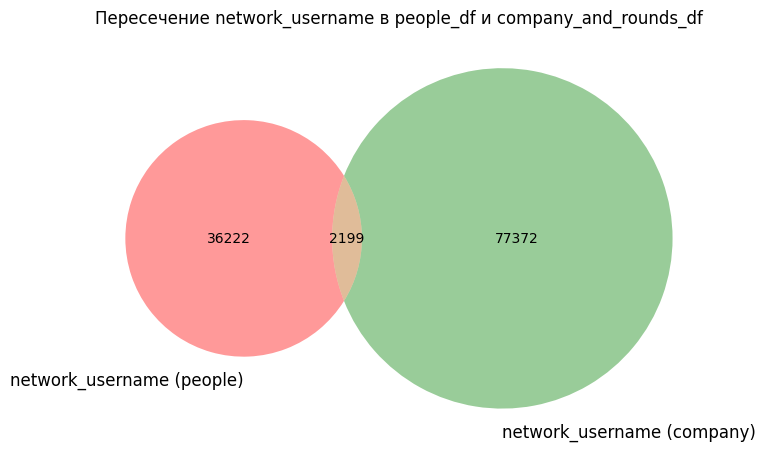

In [ ]:
# Преобразуем столбцы в множества
people_users = set(people_df['network_username'].dropna())
company_users = set(company_and_rounds_df['network_username'].dropna())

# Строим диаграмму Венна
plt.figure(figsize=(8,8))
venn2([people_users, company_users], set_labels=('network_username (people)', 'network_username (company)'))
plt.title('Пересечение network_username в people_df и company_and_rounds_df')

# Отображаем график
plt.show()

На диаграмме видно, что из всех уникальных значений network_username в people_df (36222) и company_and_rounds_df (77372) только 2199 совпадают. Это очень маленькая доля относительно общего количества. Пересечение минимально, что подтверждает предварительный анализ: столбцы `network_username` в разных датасетах представляют разные сущности (сотрудников и компании) и не подходят для объединения данных.


### 2.4. Проблемный датасет и причина возникновения пропусков

Во время собственного анализа данных у заказчика больше всего вопросов возникло к датасету `company_and_rounds.csv`. В нём много пропусков как раз в информации о раундах, которая заказчику важна.

- Необходимо: любым удобным способом приведите данные в вид, который позволит в дальнейшем проводить анализ в разрезе отдельных компаний. Необходимо: обратить внимание на структуру датасета, порядок и названия столбцов, проанализировать значения.

По гипотезе заказчика данные по компаниям из этой таблицы раньше хранились иначе, более удобным для исследования образом.

- Необходимо: максимальным образом сохраняя данные, сохранив их связность и исключив возможные возникающие при этом ошибки, подготовьте данные так, чтобы удобно было отобрать компании по параметрам и рассчитать показатели из расчёта на одну компанию без промежуточных агрегаций.

При первичном знакомстве с датасетом `company_and_rounds.csv` мы определили следующее.

**Датафрейм `company_and_rounds_df`: 217774 строки и 22 столбца** <br>
1) **Ключевые столбцы** в датасете — это два столбца с идентификатором компании. Столбец `company_id_full` с 217472 значениями без пропусков и `company_id`c 52928 значениями без пропусков (из них 31939 уникальные). При этом `company_id_full` содержит 0.1% пропусков, а в `company_id` 75.7%. Мы предполагает, что этот датасет возник благодаря объединению двух таблиц по идентификатору id компании (с типом объединения outer, который предполагает включение всех строк из обоих датафреймов и заполнение отсутствующих значений). Заметно, что одна таблица несла скорее общую информацию о компаниях, а другая информацию о каждом финансовом раунде компании. <br>
В целом исходный датасет `company_and_rounds.csv` содержит как агрегированную информацию о компаниях, так и детальные данные о каждом раунде финансирования. Можно разделить датасет на две таблицы: компании (company) и раунды (rounds).

2) В датасете 217774 строки, **пропуски** содержатся во всех столбцах, но их количество варьируется. Также отметим, что хотя в столбцах `investment  rounds`, `funding  rounds`, `funding  total`, `milestones` есть незначительное число пропусков, в них также встречаются значения 0.

3) Во многих столбцах, имеющих числовой тип данных, помимо пропусков, еще есть **нулевые значения**.<br>

4) **Явных дубликатов** в датафрейме нет. Также нет **неполных дубликатов** одновременно по id компании и id раунда финансирования.



Определим, какие поля войдут в датафреймы <br>

**Таблица компаний (companies_df)**<br>
В неё стоит включить следующие поля:<br>
`company_id_full` — уникальный идентификатор компании<br>
`name` — название компании<br>
`category_code` — категория компании<br>
`status` — статус компании (operating, acquired, closed, ipo)<br>
`founded_at`, `closed_at` — даты основания и закрытия<br>
`funding_rounds`, `investment_rounds` — число раундов<br>
`funding_total` — суммарное финансирование<br>
`milestones` — количество достижений/этапов финансирования<br>
Эти поля описывают компанию в целом (одной строкой) и позволяют анализировать её показатели на уровне всей компании.<br>

**Таблица раундов** (rounds_df)<br>
В неё стоит включить:
`funding_round_id` — уникальный идентификатор раунда
`company_id`, `company_id_full` — id компании
`funded_at` — дата раунда
`funding_round_type` — тип раунда (series-a, series-b, seed и т.д.)
`raised_amount` — сумма привлечённых средств
`pre_money_valuation` — предварительная оценка компании
`participants` — количество участников
`is_first_round`, `is_last_round` — индикаторы первого и последнего раунда
`funded_year` — год проведения раунда (добавляется для удобства анализа динамики).
Обоснование: эта таблица позволяет изучать каждый раунд отдельно, анализировать динамику финансирования, типы раундов, суммы и участников.

Перед тем как приступить к преобразованию датасета в два датафрейма, необходимо выполнить следуюшие действия, которые мы определили на предыдущим этапе.<br>
В столбцах с типом данных `float64` `milestones`, `funding_round_id`, `company_id`, `participants`, `is_first_round`, `is_last_round` и других необходимо будет понизить разрядность.<br>

In [ ]:
# Понизим разрядность вещественных числовых данных
# Для этого используем цикл for

for column in ['company_id_full', 'investment_rounds', 'funding_rounds', 'milestones', 'funding_round_id', 'company_id', 'participants', 'is_first_round', 'is_last_round']:
    company_and_rounds_df[column] = pd.to_numeric(company_and_rounds_df[column], downcast='float')

In [ ]:
# Проверяем результат преобразования
company_and_rounds_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217774 entries, 0 to 217773
Data columns (total 23 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   company_id_full      217472 non-null  float32       
 1   name                 217471 non-null  object        
 2   category_code        143886 non-null  object        
 3   status               217472 non-null  object        
 4   founded_at           109956 non-null  datetime64[ns]
 5   closed_at            3449 non-null    datetime64[ns]
 6   domain               147159 non-null  object        
 7   network_username     95534 non-null   object        
 8   country_code         108607 non-null  object        
 9   investment_rounds    217472 non-null  float32       
 10  funding_rounds       217472 non-null  float32       
 11  funding_total        217472 non-null  float64       
 12  milestones           217472 non-null  float32       
 13  funding_round_

Датасет `company_and_rounds.csv` содержит информацию о компаниях и их финансовых раундах. Для удобного анализа данные было решено разделить на две таблицы: companies_df — агрегированные данные на уровне компании (название, категория, статус, даты основания/закрытия и т.д. ), rounds_df — информация по каждому раунду (идентификаторы, даты, тип раунда, суммы, участники и т.д.). Проведено преобразование типов: даты приведены к datetime64, числовые столбцы понижены в разрядности. В целом таблицы готовы для дальнейшего анализа на уровне отдельных компаний и их раундов финансирования, с сохранением связности данных и минимизацией потерь информации.

In [ ]:
# Создаем таблицу компаний
company_columns = [
    'company_id_full', 'name', 'category_code', 'status',
    'founded_at', 'closed_at', 'funding_rounds', 'investment_rounds',
    'funding_total', 'milestones'
]
companies_df = company_and_rounds_df[company_columns].dropna(subset=['company_id_full']).drop_duplicates(subset='company_id_full')

# Создаем таблицу раундов
round_columns = [
    'funding_round_id', 'company_id', 'company_id_full',
    'funded_at', 'funding_round_type', 'raised_amount',
    'pre_money_valuation', 'participants', 'is_first_round', 'is_last_round'
]
rounds_df = company_and_rounds_df[round_columns].dropna(subset=['funding_round_id'])


In [ ]:
# Проверяем размер датафреймов и структуры
print("Размер таблицы компаний:", companies_df.shape)
display(show_missing_stats(companies_df))
print("\nРазмер таблицы раундов:", rounds_df.shape)
display(show_missing_stats(rounds_df))

Размер таблицы компаний: (196553, 10)


,Кол-во пропусков,Доля пропусков
name,1,0.000000
category_code,73367,0.373300
founded_at,105326,0.535900
closed_at,193933,0.986700



Размер таблицы раундов: (52928, 10)


,Кол-во пропусков,Доля пропусков
company_id_full,302,0.005700
funded_at,248,0.004700



## Шаг 3. Исследовательский анализ объединённых таблиц




### 3.1. Объединение данных

Объединим данные для ответа на вопросы заказчика, которые касаются интересующих его компаний. Заказчика прежде всего интересуют те компании, которые меняли или готовы менять владельцев. Получение инвестиций или финансирования, по мнению заказчика, означает интерес к покупке или продаже компании.

В качестве основы для объединённой таблицы возьмём данные из обработанного датасета `company_and_rounds.csv` — выберим только те компании, у которых указаны значения `funding_rounds` или `investment_rounds` больше нуля, или те, у которых в колонке `status` указано `acquired`. В результирующей таблице должно получиться порядка 40 тысяч компаний.

Проверьте полноту и корректность получившейся таблицы. Далее работайте только с этими данными.

Создадим новый датафрейм `companies_filtered_df` с помощью фильтрации по условиям обозначенным выше.

In [ ]:
# Фильтруем данные по условиям и сохраняем отобранные строки в датафрейме companies_filtered_df
companies_filtered_df = companies_df[
    (companies_df['funding_rounds'] > 0) |
    (companies_df['investment_rounds'] > 0) |
    (companies_df['status'] == 'acquired')]


In [ ]:
# Отобразим статистику по количеству и доле пропусков в новом датафрейме companies_filtered_df

show_missing_stats(companies_filtered_df)

,Кол-во пропусков,Доля пропусков
category_code,5432,0.133300
founded_at,12940,0.317600
closed_at,38619,0.947800


In [ ]:
# Проверяем размер датафрейма companies_filtered_df и количество уникальных компаний
columns_to_check = ['company_id_full']
print_count_uniq_values(companies_filtered_df, columns_to_check)


Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 40747

Количество уникальных значений в company_id_full: 40747


In [ ]:
# Выведем информацию по датафрейму companies_filtered_df
companies_filtered_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40747 entries, 0 to 217469
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   company_id_full    40747 non-null  float32       
 1   name               40747 non-null  object        
 2   category_code      35315 non-null  object        
 3   status             40747 non-null  object        
 4   founded_at         27807 non-null  datetime64[ns]
 5   closed_at          2128 non-null   datetime64[ns]
 6   funding_rounds     40747 non-null  float32       
 7   investment_rounds  40747 non-null  float32       
 8   funding_total      40747 non-null  float64       
 9   milestones         40747 non-null  float32       
dtypes: datetime64[ns](2), float32(4), float64(1), object(3)
memory usage: 2.8+ MB


Мы получили таблицу с 40747 компаниями, которые получали инвестиции или финансировании, или были приобетены. Пропуски содержаться только в столбцах `category_code`, `founded_at` и `closed_at`. Эти столбцы не имеют критического значения для дальнейшего анализа.


### 3.2. Анализ выбросов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

- По предобработанному столбцу `funding_total` графическим способом оценим, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся.
- В процессе расчёта значений обратим внимание, например, на показатели, возвращаемые методом `.describe()`, — их необходимо объяснить. Применимы ли к таким данным обычные способы нахождения типичных значений?

При первичном знакомстве с датасетами мы обнаружили, что в таблице company_and_rounds_df некоторые поля с числовыми данными содержат нулевые значения. Определим количество и долю этих значений в поле `funding_total`, которое содержит информацию об общем финансировании компании.

In [ ]:
columns_to_check = ['funding_total']
print_non_zero_values(companies_filtered_df, columns_to_check)
print('Доля нулевых значений в funding_total:')
display(((companies_filtered_df['funding_total'] == 0).sum() / len(companies_filtered_df)).round(2))

Размер датафрейма: 40747

Количество значений без пропусков (NaN) в funding_total:  40747
Количество значений 0 в funding_total:  12873
Количество значений без пропусков (NaN) и без 0 в funding_total:  27874
--------------------------------------------------------------------------------
Доля нулевых значений в funding_total:


np.float64(0.32)

Поле `funding_total` содержит 12873 нулевых значений, что составляет 32% от общего числа значений. Очевидно, что это будет влиять на распределение данных по общему финансированию компаний.
Теперь построим гистограмму распределения и диаграмму размаха по общему финансированию для одной компании.

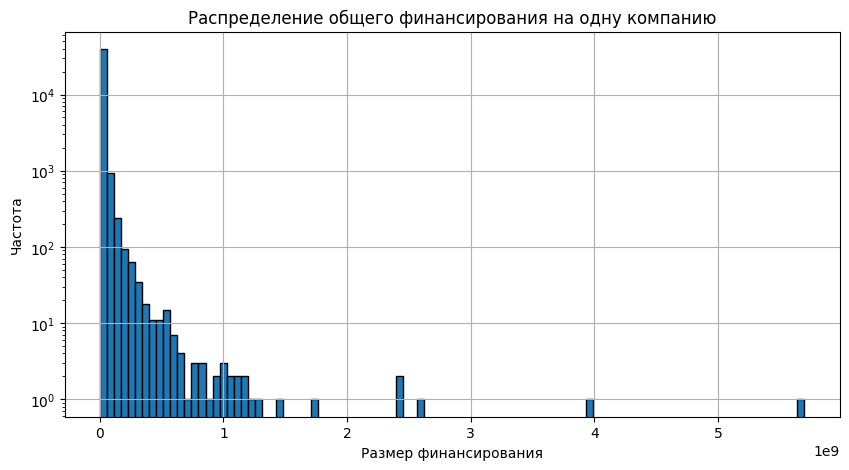

In [ ]:
# Для иллюстрации построим гистограмму распределения общего финансирования для одной компании

# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10,5))

# Строим гистограмму с помощью pandas через plot(kind='hist')
companies_filtered_df['funding_total'].plot(kind='hist',
                                            bins=100,
                                            edgecolor='k')
# Настраиваем оформление графика
plt.title('Распределение общего финансирования на одну компанию')
plt.xlabel('Размер финансирования')
plt.ylabel('Частота')

# Ставим логарифмическую шкалу для лучше визуализации перекошенного распределения
plt.yscale('log')

# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()


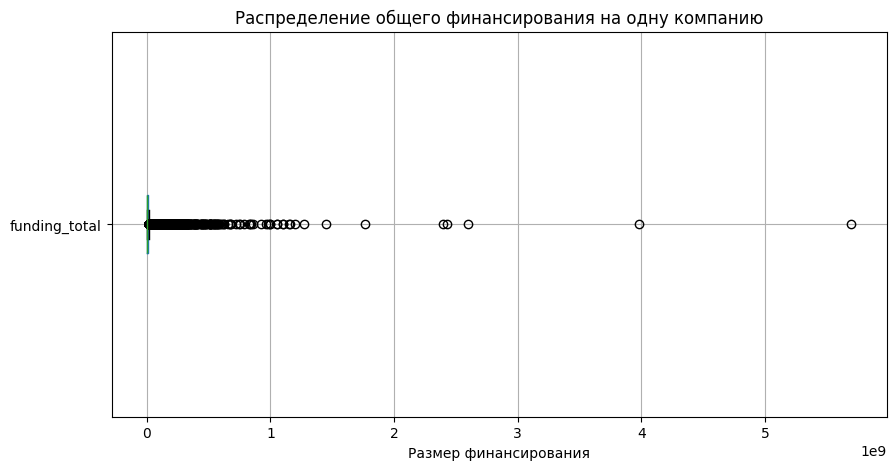

In [ ]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим диаграмму размаха значений в столбце seats
companies_filtered_df.boxplot(column='funding_total', vert=False)

# Добавляем заголовок и метки оси
plt.title('Распределение общего финансирования на одну компанию')
plt.xlabel('Размер финансирования')

# Выводим график
plt.show()

Построем диграмму размаха еще раз с параметром showfliers=False, чтобы увидеть основной диапазон.

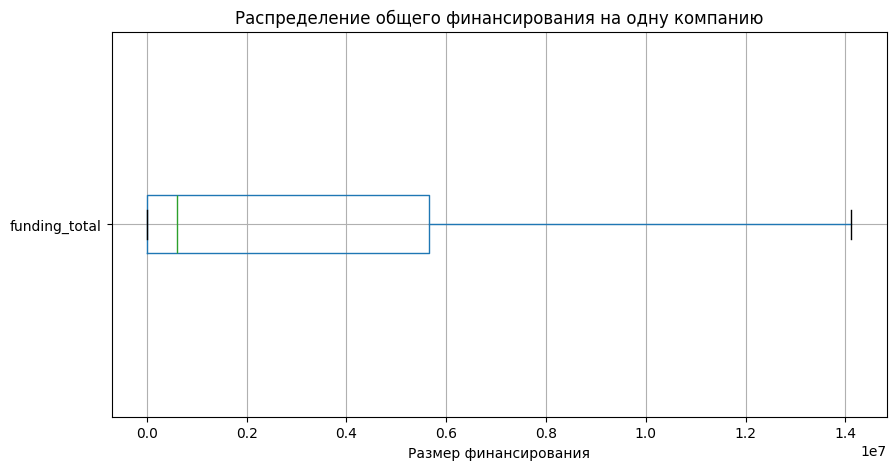

In [ ]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим диаграмму размаха значений в столбце seats
companies_filtered_df.boxplot(column='funding_total', vert=False, showfliers=False)

# Добавляем заголовок и метки оси
plt.title('Распределение общего финансирования на одну компанию')
plt.xlabel('Размер финансирования')

# Выводим график
plt.show()

Гистограмма показывает, что распределение общего финансирования для одной компании асимметричное и скошено вправо. Но при этом заметно, что нулевые значения встречаются в данных чаще всего.  Диаграмма размаха демонстрирует экстримально большие значения общего финансирования компаний. Далее рассмотрим описательную статистику.

In [ ]:
# Посмотрим на описательную статистику по полю funding_total
companies_filtered_df['funding_total'].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

,funding_total
count,4.074700e+04
mean,1.013561e+07
std,5.646436e+07
min,0.000000e+00
5%,0.000000e+00
25%,0.000000e+00
50%,6.000000e+05
75%,5.650650e+06
95%,4.350000e+07
99%,1.339487e+08


Теперь вычислим выбросы в размере финансирования.

In [ ]:
# Вычисляем первый и третий квартиль (25% и 75%) для funding_total
# Предварительно сохраним в переменной funding данные о стоимости финансирования
funding = companies_filtered_df['funding_total']

# Вычисляем квартиль (25% и 75%)
Q1 = funding.quantile(0.25)
Q3 = funding.quantile(0.75)

# Вычисляем межквартильный размах
IQR = Q3 - Q1

# Определяем границы выбросов справа в распределении
upper_bound = Q3 + 1.5 * IQR

# Определяем, каким процентилям соответствуют границы
upper_percentile = (funding <= upper_bound).mean()

print(f'Верхняя граница выбросов: {upper_bound:.2f}')
print(f'Верхняя граница соответствует примерно {upper_percentile:.2%} данных')

Верхняя граница выбросов: 14126625.00
Верхняя граница соответствует примерно 85.62% данных


Распределение финансирования сильно скошено вправо: большинство значений относительно небольшие, медиана 600 тыс, среднее около 10 млн, что сильно завышено из-за крупных сделок. Медиана более устойчива к выбросам, но из-за большого числа нулевых значений она может недооценивать типичное финансирование. Ниже мы расчитаем медиану для ненулевого финансирования.<br>
Верхняя граница выбросов по IQR равна 14.13 млн — примерно 14.38% компаний имеют финансирование выше этой суммы и могут считаться выбросами.
25–75-й перцентиль показывает, что типичный размер финансирования для большинства компаний находится в диапазоне от нескольких сотен тысяч до нескольких миллионов.


In [ ]:
#  Расчитаем медиану по ненулевым значениям
median_nonzero = companies_filtered_df.loc[companies_filtered_df['funding_total'] > 0, 'funding_total'].median()
print('Медиана по ненулевым значениям:', median_nonzero)

Медиана по ненулевым значениям: 2564500.0


Таким образом, большинство компаний привлекли относительно небольшое финансирование — от сотен тысяч до нескольких миллионов, медиана по ненулевым значениям составляет 2.56 млн. Примерно 14% компаний получили суммы выше 14,13 млн, которые можно считать выбросами.


### 3.3. Куплены забесплатно?

- Исследуем компании, которые были проданы за ноль или за один доллар, и при этом известно, что у них был ненулевой общий объём финансирования.

- Рассчитаем аналитически верхнюю и нижнюю границу выбросов для столбца `funding_total` и укажим, каким процентилям границы соответствуют.

In [ ]:
# Выведем еще раз одновременно покупающие и продаваемые компании, чей индентификатор встречается более одного раза, с помощью метода duplicated()
acquisition_df[acquisition_df.duplicated(subset=['acquired_company_id', 'acquiring_company_id'], keep=False)].sort_values('acquired_company_id')

,id,acquiring_company_id,acquired_company_id,term_code,price_amount,acquired_at
7581,8454,317,1612,NaN,150000000,2013-03-29
7562,8435,317,1612,NaN,0,2013-03-28
1600,1875,317,2279,NaN,0,2008-08-24
620,762,317,2279,NaN,0,2008-08-25
429,542,59,10963,NaN,0,2008-09-12
2167,2484,59,10963,NaN,0,2008-09-12
589,725,317,13089,NaN,0,2008-10-20
2165,2481,317,13089,NaN,0,2008-10-22
9352,10469,157289,39040,NaN,0,2013-12-04
9355,10472,157289,39040,NaN,0,2013-12-04


В большинстве случаев дубликаты касаются продаж с нулевой суммой. У нас есть только два случая, когда одна компания купила другую сначала за 0, а потом за ненулевую стоимость. Удилим в этом случае продажи с нулевой стоимостью по индексу, а после удалим все неполные (неявные) дубликаты.

In [ ]:
# Удалим строку по индексу
acquisition_df = acquisition_df.drop(7136).reset_index(drop=True)

# Удалим неполные дубликаты по покупающей и продаваемой компаниям
acquisition_cleaned_df = acquisition_df.drop_duplicates(subset=['acquired_company_id', 'acquiring_company_id'],
                                                       keep='first').reset_index(drop=True)


Теперь переходим к объединению таблиц `acquisition_df` и `companies_filtered_df`.

In [ ]:
# Объединяем acquisition_df и companies_filtered_df
merged_df = companies_filtered_df.merge(acquisition_cleaned_df[['acquired_company_id', 'term_code', 'acquired_at','price_amount']],
                                        left_on='company_id_full', right_on='acquired_company_id', how='inner' )



Теперь мы отфильтруем данные по условиям, чтобы получить датафрейм с интересующими нас компаниями.

In [ ]:
# Фильтруем данные по условиям задачи:
# компании куплены за 0 или 1 доллар;
# имеют ненулевой объём финансирования.
filtered_null_zero_price = merged_df[
    (merged_df['price_amount'].isin([0, 1]) &
    (merged_df['funding_total'] > 0))
].copy().reset_index(drop=True)

Проверяем отфильтрованную по условиям таблицу `filtered_null_zero_price`.

In [ ]:
# Выведем первые строки merged_companies
display(filtered_null_zero_price.head(10))
# Выведем информацию по merged_companies
display(filtered_null_zero_price.info())

,company_id_full,name,category_code,status,founded_at,closed_at,funding_rounds,investment_rounds,funding_total,milestones,acquired_company_id,term_code,acquired_at,price_amount
0,10054.0,Jumptap,mobile,acquired,2005-01-01,NaT,7.0,0.0,121500000.0,3.0,10054,cash_and_stock,2013-08-13,0
1,101312.0,SideTour,web,acquired,2011-06-01,NaT,3.0,0.0,4000000.0,2.0,101312,NaN,2013-09-18,0
2,101340.0,ChoicePass,enterprise,acquired,2011-07-01,NaT,1.0,0.0,250000.0,1.0,101340,NaN,2012-06-18,0
3,10137.0,Producteev,software,acquired,2008-07-08,NaT,3.0,0.0,1310000.0,2.0,10137,cash_and_stock,2012-11-05,0
4,10139.0,TradeCard,enterprise,acquired,1999-01-01,NaT,2.0,0.0,44925000.0,1.0,10139,NaN,2013-04-01,0
5,10179.0,GoodGuide,web,acquired,2007-12-01,NaT,3.0,0.0,14230000.0,3.0,10179,NaN,2012-08-09,0
6,10199.0,Where I've Been,travel,acquired,2007-06-08,NaT,2.0,0.0,1750000.0,2.0,10199,NaN,2011-07-11,0
7,10200.0,Swype,software,acquired,2002-01-01,NaT,5.0,0.0,13900000.0,3.0,10200,NaN,2011-10-06,0
8,10252.0,Mob.ly,mobile,acquired,2007-10-01,NaT,1.0,0.0,1100000.0,2.0,10252,NaN,2010-05-05,0
9,10273.0,Angstro,software,acquired,2007-04-27,NaT,1.0,0.0,225000.0,0.0,10273,NaN,2010-08-27,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1615 entries, 0 to 1614
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   company_id_full      1615 non-null   float32       
 1   name                 1615 non-null   object        
 2   category_code        1550 non-null   object        
 3   status               1615 non-null   object        
 4   founded_at           1283 non-null   datetime64[ns]
 5   closed_at            13 non-null     datetime64[ns]
 6   funding_rounds       1615 non-null   float32       
 7   investment_rounds    1615 non-null   float32       
 8   funding_total        1615 non-null   float64       
 9   milestones           1615 non-null   float32       
 10  acquired_company_id  1615 non-null   int64         
 11  term_code            121 non-null    object        
 12  acquired_at          1611 non-null   datetime64[ns]
 13  price_amount         1615 non-nul

None

Дополнительно вычислим долю компаний, преобретенных за 0 или 1 доллар, от общего количества проданных компаний и от количества компаний, по которым известна стоимость продажи. Количество приобретенных компаний — это размер датафрейма `companies_filtered_df`: в нем все компании имеют статус "продано". Количество компаний, по которым известна стоимость продажи, — это размер датафрейма `acquisition_cleaned_df`: в нем нет пропусков в поле с информацией о стоимости продажи.

In [ ]:
print(f'Общее количество проданных компаний: {len(companies_filtered_df)}')
print(f"Компаний куплено за 0/1 доллар с финансированием: {len(filtered_null_zero_price)}")
print(f"Доля от всех приобретенных: {len(filtered_null_zero_price)/len(companies_filtered_df):.2}")
print(f"Доля от всех приобретенных со стоимостью продажи: {len(filtered_null_zero_price)/len(acquisition_cleaned_df):.2}")



Общее количество проданных компаний: 40747
Компаний куплено за 0/1 доллар с финансированием: 1615
Доля от всех приобретенных: 0.04
Доля от всех приобретенных со стоимостью продажи: 0.17


Всего 1618 компаний были приобретены за 0 или 1 доллар, что около 17% от числа всех проданных компаний, и 4% от количества компаний, по которым есть информация остоимости продажи.<br>
Исследуем эти компании со стоимость 0 и 1 детальнее. Посмотрим, сколько компаний было продано за 0 и за 1 доллар, а затем проверим, в каких отраслях чаще происходили такие сделки.

In [ ]:
# Посчитаем количества значений в поле price_amount со стоимостью покупик компании 0 и 1
filtered_null_zero_price['price_amount'].value_counts()

,count
price_amount,
0,1615


В датафрейме `filtered_null_zero_price` остались компании со стоимостью продажи 0. Значит компании, проданные за 1 доллар, не получали финансирования и из-за этого не попали в итоговую таблицу. Проверим это и выведем компании со стоимостью 1 доллар, но не получавшие финансирование.

In [ ]:
# Выводим строки с компаниями за 1 доллар
merged_df[merged_df['price_amount'] == 1]

,company_id_full,name,category_code,status,founded_at,closed_at,funding_rounds,investment_rounds,funding_total,milestones,acquired_company_id,term_code,acquired_at,price_amount
2974,236268.0,ItIsWhatIt.Is,other,acquired,2013-04-01,NaT,0.0,0.0,0.0,0.0,236268,cash,2013-09-30,1
3742,266297.0,Online Tech Pc,NaN,acquired,NaT,NaT,0.0,0.0,0.0,0.0,266297,cash,2013-08-13,1
4254,283073.0,Catherine Price Acupuncture,NaN,acquired,NaT,NaT,0.0,0.0,0.0,0.0,283073,NaN,2007-01-01,1


Получается, что в рамках настоящей задачи мы имеем дело только с компаниями, проданным за нулевую стоимость.<br> Теперь проверим, в каких отраслях чаще встречаются продажи компаний за 0 (и ненулевым финансированием) и сравним их с распределеним отраслей у компаний, проданных не за нулевую стоимость. Будем сравнимать в относительных значениях, потому что количество компаний в этих группах различаются.

In [ ]:
# Выведем топ-10 отраслей компаний, проданных за 0
print('Топ-10 отраслей компаний, проданных за 0:')
display(filtered_null_zero_price['category_code'].value_counts(normalize=True).head(10).round(3))
print()
print('Топ-10 отраслей компаний, проданных за ненулевую стоимость:')
display(merged_df['category_code'].value_counts(normalize=True).head(10).round(3))



Топ-10 отраслей компаний, проданных за 0:


,proportion
category_code,
software,0.234
web,0.139
enterprise,0.085
mobile,0.075
advertising,0.049
games_video,0.049
biotech,0.045
ecommerce,0.039
network_hosting,0.036



Топ-10 отраслей компаний, проданных за ненулевую стоимость:


,proportion
category_code,
software,0.222
web,0.150
biotech,0.069
mobile,0.063
enterprise,0.063
games_video,0.052
other,0.048
advertising,0.048
ecommerce,0.042


В целом не наблюдается каких-то существенных отличий в том, в каких отраслях чаще происходит продажи компаний за 0. Также приобладают компании в области software и web. <br>
Теперь попробуем сравнить размер привлечённых инвестиций у компаний, проданных за 0, и у компаний с ненулевой ценой.

In [ ]:
# Сначала отфильтруем компании, проданные за ненулевую стоимость и привлекающие ненулевое финансирование,
# используя датафрейм merged_df
non_zero_sales = merged_df[(merged_df['price_amount'] > 0) & (merged_df['funding_total'] > 0)]

# Считаем количество, среднее, медиану, минимальное и максимальное значение по funding_total
# для компаний, проданных за 0, и комавний за ненулевую стоимость
agg_zero = filtered_null_zero_price['funding_total'].describe()
agg_nonzero = non_zero_sales['funding_total'].describe()

print('Компании, проданные за 0:')
display(agg_zero)

print('Компании, проданные за ненулевую стоимость:')
display(agg_nonzero)

Компании, проданные за 0:


,funding_total
count,1.615000e+03
mean,1.818182e+07
std,1.446357e+08
min,3.750000e+03
25%,2.000000e+06
50%,6.000000e+06
75%,1.550000e+07
max,5.700000e+09


Компании, проданные за ненулевую стоимость:


,funding_total
count,7.300000e+02
mean,3.145313e+07
std,5.886339e+07
min,1.500000e+04
25%,6.000000e+06
50%,1.500000e+07
75%,3.389500e+07
max,8.357500e+08


Компании, которые были проданы за деньги, обычно привлекали больше инвестиций. Их медиана почти в 3 раза выше, чем у нулевых сделок. Нулевые сделки характерны для компаний с относительно небольшим финансированием, хотя есть и очень большие продажи за 5.7 млрд (возможно, выброс или аномальное значение). Проданные за деньги компании, по всей видимости, чаще имеют более высокое финансирование и представляют ценность для покупателя.<br>
Теперь прейдем к задаче по расчету верхней и нижней границы выбросов для столбца funding_total и укажим, каким процентилям границы соответствуют.

In [ ]:
# Вычисляем первый и третий квартиль (25% и 75%) для funding_total
# Предварительно сохраним в переменной funding_null данные о стоимости финансирования
funding_null = filtered_null_zero_price['funding_total']

# Вычисляем квартиль (25% и 75%)
Q1 = funding_null.quantile(0.25)
Q3 = funding_null.quantile(0.75)

# Вычисляем межквартильный размах
IQR = Q3 - Q1

# Определяем границы выбросов
# Нижняя граница не может быть отрицательной, т.к. объём инвестиций >= 0,
# поэтому устанавливаем её в 0, если формула даёт отрицательное значение
lower_bound = max(0, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

print(f'Нижняя граница выбросов: {lower_bound:.2f}')
print(f'Верхняя граница выбросов: {upper_bound:.2f}')

# Определяем, каким процентилям соответствуют границы
lower_percentile = (funding_null <= lower_bound).mean()
upper_percentile = (funding_null <= upper_bound).mean()

print(f'Нижняя граница соответствует примерно {lower_percentile:.2%} данных')
print(f'Верхняя граница соответствует примерно {upper_percentile:.2%} данных')


Нижняя граница выбросов: 0.00
Верхняя граница выбросов: 35750000.00
Нижняя граница соответствует примерно 0.00% данных
Верхняя граница соответствует примерно 90.90% данных


Объём инвестиций не может быть отрицательным, поэтому нижняя граница выбросов равна 0. Верхняя граница выбросов равна 357.5 млн и соответствует примерно 90,9% данных. Это значит, что около 9% компаний имеют объём финансирования, значительно превышающий типичный диапазон. Таким образом, для большинства компаний, проданных за 0 и с ненулевым финансированием, привлечённый капитал не превышает 35,75 млн, а редкие стартапы с большим финансированием можно считать выбросами.

Мы исследовали компании, проданные за 0 или 1 доллар, с ненулевым общим объёмом финансирования. Bз анализа видно, что из всех проданных компаний лишь небольшая часть — около 4% — попала в категорию с ненулевым финансированием. При этом из всех компаний, про которые известна стоимость продажи, компании с нулевой стоимостью составили около 17%. Большинство сделок за 1 доллар или больше не попали в фильтр из-за отсутствия финансирования. В итоге в выборку попали только компании, проданные за 0, так как компании за 1 не имели финансирования. Наиболее распространённые отрасли — software и web, существенных отличий от компаний с ненулевой стоимостью продаж нет. Средний объём финансирования у компаний за 0 составляет около 18 млн, медиана — 6 млн, тогда как у компаний с ненулевой стоимостью продажи медиана в 2.5 раза выше (15 млн). Нижняя граница выбросов по funding_total равна 0 (объём инвестиций не может быть отрицательным), верхняя — 35,75 млн, что соответствует 90,9% данных. Таким образом, около 9% компаний имеют аномально высокий объём финансирования.<br>
Таким образом, большинство компаний, проданных за 0, имели относительно небольшое финансирование, редкие высокофинансированные компании являются выбросами, а продажи за деньги чаще связаны с компаниями, привлекшими значительный капитал.<br>  




### 3.4. Цены стартапов по категориям

Категории стартапов с типично высокими ценами покупки стартапов и значительным разбросом цен могут быть привлекательными для крупных инвесторов, которые готовы к высоким рискам ради потенциально больших доходов. Среди категорий стартапов выделите категории стартапов, характеризующиеся:

- типично высокими ценами;
- и наибольшим разбросом цен за стартап.

Необходимо объяснить, почему решили составить топ именно из такого числа категорий и почему рассчитывали именно так.

Будем работать с таблицей `merged_df`, где есть информация о цене продажи `price_amount` и категории компании `category_code`. Рассчитаем ключевые статистики по категориям: медиану `price_amount` (она менее чувствительна к выбросам, чем среднее) и межквартильный размах (IQR) или стандартное отклонение (std).

Для оценки категорий стартапов с высокими ценами и значительным разбросом исключаем сделки за 0, чтобы не искажать аналитические выводы. Сделки за 0 могут быть интересны как отдельная категория, но не для оценки типичных цен. Также важно учитывать, что в категориях с небольшим числом компаний статистики (медиана, стандартное отклонение) нестабильны: один выброс сильно влияет на показатели. Для надёжности будем использовать категории с ≥30 компаниями — эмпирическое правило, основанное на центральной предельной теореме, которое помогает получить более устойчивые показатели, даже если распределения не нормальные. Мы выборем топ-10 компаний по практическим целям: это позволяет сфокусироваться на наиболее значимых для инвесторов категориях.

In [ ]:
# Фильтруем компании, проданные за ненулевую стоимость
non_zero_sales = merged_df[merged_df['price_amount'] > 0].copy()

# Группируем по категориям и считаем медиану, стандартное отклонение и количество компаний
# Отсортируем строки по медиане и стандартному отклонению
category_stats = non_zero_sales.groupby('category_code')['price_amount'].agg(
    median_price='median',
    price_std='std',
    company_count='count'
).sort_values(by=['median_price', 'price_std', 'company_count'], ascending=False)

# Выводим топ-10 компаний
display(category_stats[category_stats['company_count'] >= 30].head(10))



,median_price,price_std,company_count
category_code,,,
biotech,200000000.0,1.968195e+09,263
cleantech,185000000.0,8.744196e+08,39
ecommerce,180000000.0,2.823312e+08,49
security,164500000.0,1.378442e+09,36
public_relations,110000000.0,6.854338e+09,74
network_hosting,102500000.0,6.769568e+08,64
semiconductor,100000000.0,1.122025e+09,71
hardware,76000000.0,6.450874e+08,78
other,71550000.0,2.060861e+09,84


Отрасли компании были отсортированы по медианной стоимости, а затем по разбросу цен. Лидером в этом случае оказалась категория `biotech` (200 млн — медиана, около 1.9 млрд — старндартное отклонение). Более того, мы учли количество проданных компаний в отраслях и большое число компаний в `biotech` указывает на высокую ценность и активность в инвестициях в этой отрасли.<br> Высокое стандартное отклонение в категориях, таких как `public_relations` (6.85 млрд), указывает на значительный разброс цен. Остальные категории с высоким медианным уровнем цен и значительным числом компаний (например, `cleantech`, `ecommerce` `security`) также представляют интерес для крупных инвесторов. Таким образом, данный анализ помогает выделить категории стартапов, которые потенциально привлекательны для инвесторов, готовых к рискам ради высоких доходов.


### 3.5. Сколько раундов продержится стартап перед покупкой

- Необходимо проанализировать столбец `funding_rounds`. Исследуйте значения столбца. Заказчика интересует типичное значение количества раундов для каждого возможного статуса стартапа.
- Построим график, который отображает, сколько в среднем раундов финансирования проходило для стартапов из каждой группы. Сделаем выводы.

Для начала проведем исследование столбца `funding_rounds`.

In [ ]:
# Выведем частоту встречаемости значений с помощью метода value_counts()
funding_rounds_stats = pd.DataFrame({
        'Кол-во значений': companies_df['funding_rounds'].value_counts(),
        'Доля значений': companies_df['funding_rounds'].value_counts(normalize=True).round(4)
})
display(funding_rounds_stats)

,Кол-во значений,Доля значений
funding_rounds,,
0.0,164846,0.8387
1.0,20534,0.1045
2.0,6142,0.0312
3.0,2662,0.0135
4.0,1216,0.0062
5.0,600,0.0031
6.0,249,0.0013
7.0,147,0.0007
8.0,67,0.0003


Раунды варьируются от 0 до 14. Преобладающее число раундов в данных — это 0 (83% от всех значений). Следующие по частоте встечаемости значения 1 (10%) и 2 (3%). Количество раундов больше 7 встречаются в данных крайне редко (меньше 1%). <br>
Далее выведем описательные статистики по столбцу `funding_rounds`.

In [ ]:
companies_df['funding_rounds'].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])

,funding_rounds
count,196553.000000
mean,0.267745
std,0.777781
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
95%,2.000000
99%,4.000000
max,15.000000


Распределение сильно скошено (асимметрично), так как большинство значений равны нулю. Среднее равно 0.26, а медиана 0. Медиана показывает, что у большинства стартапов не было раундов финансирования, тогда как среднее значение выше нуля из-за небольшой доли компаний, которые проходили несколько раундов. Таким образом, медиана отражает типичную ситуацию, а среднее — наличие достаточно редких случаев привлечения капитала. <br>
Теперь расчитаем среднее количество раундов финансирования, которое проходило для стартапов из каждой группы статусов.

In [ ]:
# Рассчитаем среднее количество раундов финансирования для каждой группы по статусу
funding_rounds_by_status = companies_df.groupby('status')['funding_rounds'].mean().sort_values(ascending=False)
print('Среднее количество раундов по статусам:')
display(funding_rounds_by_status)



Среднее количество раундов по статусам:


,funding_rounds
status,
closed,1.118421
ipo,1.091711
acquired,0.523526
operating,0.237570


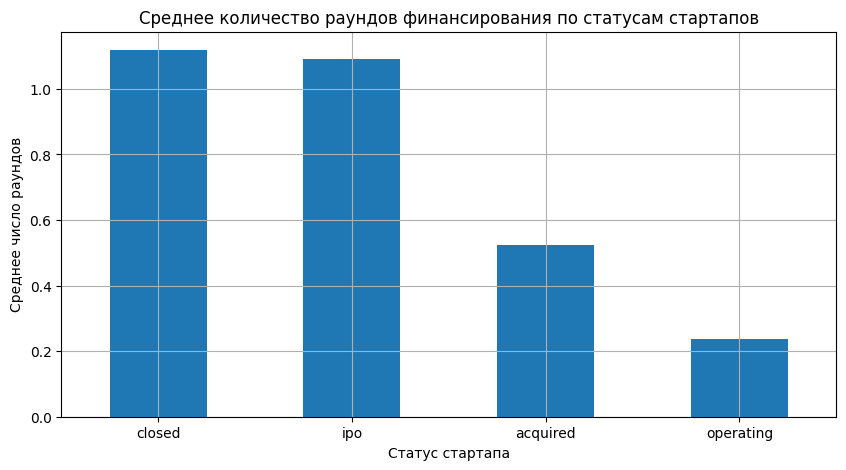

In [ ]:
# Построим столбчатую диаграмму

# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим столбчатую диаграмму
funding_rounds_by_status.plot(
               kind='bar',
               rot=0
)


plt.title('Среднее количество раундов финансирования по статусам стартапов')
plt.xlabel('Статус стартапа')
plt.ylabel('Среднее число раундов')

# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

У закрывшихся компаний (`closed`) и у компаний, которые впервые предлагают свои акции широкому кругу инвесторов, делая их доступными для покупки на фондовой бирже (Initial public offering, `ipo`), среднее число раундов больше 1. Это означает, что такие стартапы чаще всего проходили несколько раундов финансирования перед своим финальным исходом (успех в виде `ipo` или неудача в виде закрытия). Относительно высокое среднее для ipo вполне логично, потому что этот статус является результатом роста и успеха компании. С другой стороны, мы наблюдаем относительно высокое среднее для закрывшихся стартапов: некоторые из них получили несколько раундов финансирования, но в итоге не удалось сохранить бизнес. <br>

У компаний, которые были приобретены (`acquired`) среднее ниже — 0.52. Это значит, что среди них много стартапов, купленных ещё на ранних стадиях, без большого количества раундов. У действующих (`operating`) компаний среднее минимальное (0.24). Большинство таких стартапов не проходили раунды финансирования или пока находятся на ранней стадии.

## Шаг 4. Итоговый вывод и рекомендации

В рамках проекта подготовлен датасет и исследованы данные о компаниях, финансировании и сделках на рынке стартапов. Цель — предоставить финансовой компании информацию для разработки модели инвестиций по покупке, развитию и перепродаже стартапов.

### Что сделано

- Изучены размеры и структура таблиц (от 9 тыс. до 200 тыс. строк), типы данных, пропуски, явные и неявные дубликаты, ключи для объединения.
- Проанализировано финансирование по годам: максимальный типичный размер — 5.5 млн в 2005 году. К 2013 году рынок стал активнее (больше раундов), но медианные суммы снизились.
- Проверена полнота данных об образовании: около 50% сотрудников без данных. В крупных компаниях (15+) — 39.3%, в малых и средних — 46-52%.
- Столбец `network_username` в `people` содержит ник сотрудника, в `company_and_rounds` — ник компании. Объединение по нему некорректно.
- `company_and_rounds` разделён на две таблицы: компании и раунды (исходная таблица была результатом outer-объединения).

### Основные выводы

Сформирован датасет из 40 747 компаний, которые привлекали финансирование или были приобретены. Пропуски остались только в `category_code`, `founded_at`, `closed_at` — некритично.

**Финансирование.** Распределение `funding_total` скошено вправо. Среднее (примерно 10 млн.) искажено выбросами, медиана 0.6 млн. лучше отражает типичный уровень. Среди компаний с финансированием медиана — 2.56 млн.

**Продажи за 0.** 1 615 компаний (примерно 4% приобретённых) проданы за ноль при наличии финансирования. Средние инвестиции у таких компаний около 18 млн при медиане 6 млн. — следствие асимметрии. Чаще встречаются в категориях `software`, `web`, `enterprise`, `biotech`. Отраслевых отличий от компаний, проданных за деньги, нет.

**Категории.** Высокие медианные цены при значительном разбросе: `biotech`, `cleantech`, `ecommerce`, `security`, `public_relations`. Учитывались только категории с 30+ компаниями.

**Раунды.** Медиана — 0 у большинства стартапов. Среднее по статусам:

| Статус | Среднее число раундов |
|--------|----------------------|
| `closed` | 1.12 |
| `ipo` | 1.09 |
| `acquired` | 0.52 |
| `operating` | 0.24 |

`ipo` и `closed` проходят больше раундов; приобретённые компании чаще покупаются на ранних стадиях.

**Взаимосвязь.** Компании с большим числом раундов и высоким финансированием чаще доходят до `ipo` или привлекают покупателей, но это не гарантирует успеха — среднее число раундов у `closed` и `ipo` близки.

### Рекомендации

- Стартапы в категориях `biotech`, `cleantech`, `ecommerce`, `security`, `public_relations` потенциально привлекательны для крупных инвесторов.
- Количество раундов помогает предсказать стадию возможной продажи или выхода на `ipo`. Ранние приобретения чаще у малофинансируемых стартапов.
- Для оценки типичного стартапа использовать медиану и интерквартильный диапазон, а не среднее — иначе редкие крупные сделки искажают картину.
